# Target Brazil: E-commerce Operations SQL Case Study
**Author:** Guntuku Hariprasad &nbsp;·&nbsp; **Data:** 99,441 orders, Sep 2016 - Oct 2018 &nbsp;·&nbsp; **Stack:** SQL (BigQuery dialect, executed here on DuckDB), pandas, matplotlib

This notebook answers every question in the Scaler *Target SQL* business case with a SQL query, shows the result, and explains what it means for the business. Every query is written in BigQuery Standard SQL (the `bigquery` text printed above each result) and runs locally through an automatic DuckDB translation, so the notebook reproduces end to end with no cloud account.

## Executive summary
- Growth is real and volume-driven. Orders in Jan-Aug 2018 were 135% higher than in Jan-Aug 2017 and payment value rose 137%, while the average order value barely moved (R$159.7 to R$161.0). Target Brazil won more customers; it did not sell them bigger baskets.
- Growth has plateaued. Monthly orders climbed from 800 (Jan 2017) to a Black Friday peak of 7,544 (Nov 2017; 1,176 orders on Black Friday, 24 Nov, alone) and then held at roughly 6,200-7,300 a month through 2018. Year-on-year value growth fell from +705% in January to +52% in August.
- Demand is concentrated in the South-East. SP, RJ and MG hold 66.5% of customers and SP alone 41.9%. 59.7% of sellers are also in SP, so the network is effectively a single hub.
- Distance from the hub drives cost, speed and satisfaction. SP customers get orders in 8.3 days and pay R$15.15 freight per item; Roraima (RR) waits 29.0 days and pays R$42.98. Same-state orders arrive in 7.5 days vs 14.6 cross-state, with 43% lower freight.
- Lateness, not slowness, destroys ratings. Orders delivered early average 4.2-4.3 stars; orders 8+ days late average 1.70 and 70% of them get 1 star. Late rates spike after demand peaks (12.4% in Nov 2017, 19.0% in Mar 2018), so the problem is capacity, not geography alone.
- Credit card is the payment backbone (76.9% of orders, average 3.5 installments). Half of all orders are single-payment, but 10-installment plans carry the biggest tickets (R$415 average).
- Retention is the biggest untapped lever: 96.9% of customers ordered only once.

## Assumptions
- SQL is written for BigQuery (dataset `target`) and mirrored for DuckDB; both produce identical results.
- Delivery metrics use orders with status 'delivered' and a non-null delivery date (96,470 orders).
- Days are whole 24-hour periods (BigQuery TIMESTAMP_DIFF ... DAY). An order is late when diff_estimated_delivery > 0, i.e. it arrived at least one day after the estimated date.
- 'Average freight value' and 'average delivery time' by state are averaged per item and per order respectively; per-order price and freight are also reported in 4.3-4.4.
- Customer counts use customer_unique_id (one person), not customer_id (one per order).
- Payment type 'UPI' is the label used in this version of the dataset.

In [1]:
import sys, subprocess
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'scripts'))
import duckdb, pandas as pd
from IPython.display import Image, Markdown, display
from query_catalog import Q
pd.set_option('display.max_columns', 20); pd.set_option('display.width', 200)
DB = ROOT / 'target_brazil.duckdb'
if not DB.exists():  # first run: load the 8 CSVs from data/ into DuckDB
    subprocess.run([sys.executable, str(ROOT / 'scripts' / 'build_db.py')], check=True)
con = duckdb.connect(str(DB), read_only=True)
QUERIES = {q['id']: q for q in Q}

def run(qid, show_sql=True, rows=10):
    q = QUERIES[qid]
    if show_sql:
        print(q['bigquery'])
    df = con.execute(q['duckdb']).df()
    print(f'{len(df):,} rows')
    return df.head(rows)

def chart(name):
    display(Image(filename=str(ROOT / 'charts' / name), width=900))

In [2]:
con.sql("SELECT table_name, estimated_size AS approx_rows FROM duckdb_tables() WHERE schema_name = 'target' ORDER BY 2 DESC").df()

,table_name,approx_rows
0,geolocation,1000163
1,order_items,112650
2,payments,103886
3,customers,99441
4,orders,99441
5,order_reviews,99224
6,products,32951
7,sellers,3095


## 1. Initial exploration: structure & characteristics

### Q1.1 Data type of all columns in the customers table
> Data type of all columns in the "customers" table.

In [3]:
run('1.1')

SELECT
  column_name,
  data_type
FROM target.INFORMATION_SCHEMA.COLUMNS
WHERE table_name = 'customers'
ORDER BY ordinal_position;

5 rows


,column_name,data_type
0,customer_id,VARCHAR
1,customer_unique_id,VARCHAR
2,customer_zip_code_prefix,BIGINT
3,customer_city,VARCHAR
4,customer_state,VARCHAR


**Insights**
- The customers table has 5 columns. The two IDs, city and state are STRING; the zip code prefix is INT64 (stored as BIGINT locally).
- customer_id is unique per order, while customer_unique_id identifies the real person: 99,441 customer_ids map to 96,096 unique customers. Any customer count in this study uses customer_unique_id.
- Zip prefixes lose their leading zero as integers (01037 becomes 1037). They still join to geolocation correctly because both sides are integers.

**Recommendations**
- Keep zip prefixes as zero-padded STRING in the warehouse so they match postal formats when shared with logistics partners.

### Q1.2 Time range between which the orders were placed
> Get the time range between which the orders were placed.

In [4]:
run('1.2')

SELECT
  MIN(order_purchase_timestamp) AS first_order_at,
  MAX(order_purchase_timestamp) AS last_order_at,
  TIMESTAMP_DIFF(MAX(order_purchase_timestamp), MIN(order_purchase_timestamp), DAY) AS span_in_days,
  COUNT(*) AS total_orders
FROM target.orders;

1 rows


,first_order_at,last_order_at,span_in_days,total_orders
0,2016-09-04 21:15:19,2018-10-17 17:30:18,772,99441


**Insights**
- Orders span 4 Sep 2016 21:15 to 17 Oct 2018 17:30, about 772 days (25 calendar months).
- The edges are thin: Sep-Dec 2016 has 329 orders (no orders at all in Nov 2016) and Sep-Oct 2018 has 20. Year-on-year comparisons should therefore use Jan-Aug, which the brief also asks for.

**Recommendations**
- Report trends on complete months (Jan 2017 - Aug 2018) so the partial edges do not distort growth rates.

### Q1.3 Count of cities & states of customers who ordered
> Count the Cities & States of customers who ordered during the given period.

In [5]:
run('1.3')

SELECT
  COUNT(DISTINCT c.customer_city)  AS num_cities,
  COUNT(DISTINCT c.customer_state) AS num_states,
  COUNT(DISTINCT c.customer_unique_id) AS num_unique_customers,
  COUNT(DISTINCT o.order_id) AS num_orders
FROM target.orders AS o
JOIN target.customers AS c
  ON o.customer_id = c.customer_id
WHERE o.order_purchase_timestamp BETWEEN
      (SELECT MIN(order_purchase_timestamp) FROM target.orders)
  AND (SELECT MAX(order_purchase_timestamp) FROM target.orders);

1 rows


,num_cities,num_states,num_unique_customers,num_orders
0,4119,27,96096,99441


**Insights**
- Customers who ordered in the period come from 4,119 cities across all 27 Brazilian states (26 states + the Federal District).
- Those 99,441 orders were placed by 96,096 unique customers, i.e. 1.03 orders per customer.

**Recommendations**
- National reach already exists; the opportunity is deepening penetration outside the South-East, not opening new states.

### Q1.4 Data profile: row counts and key coverage for every table
> Supporting check: size of every table and how cleanly they join.

In [6]:
run('1.4')

SELECT 'orders'        AS table_name, COUNT(*) AS row_count, COUNT(DISTINCT order_id)    AS distinct_keys FROM target.orders
UNION ALL SELECT 'customers',     COUNT(*), COUNT(DISTINCT customer_id)  FROM target.customers
UNION ALL SELECT 'order_items',   COUNT(*), COUNT(DISTINCT order_id)     FROM target.order_items
UNION ALL SELECT 'payments',      COUNT(*), COUNT(DISTINCT order_id)     FROM target.payments
UNION ALL SELECT 'order_reviews', COUNT(*), COUNT(DISTINCT order_id)     FROM target.order_reviews
UNION ALL SELECT 'products',      COUNT(*), COUNT(DISTINCT product_id)   FROM target.products
UNION ALL SELECT 'sellers',       COUNT(*), COUNT(DISTINCT seller_id)    FROM target.sellers
UNION ALL SELECT 'geolocation',   COUNT(*), COUNT(DISTINCT geolocation_zip_code_prefix) FROM target.geolocation
ORDER BY row_count DESC;

8 rows


,table_name,row_count,distinct_keys
0,geolocation,1000163,19015
1,order_items,112650,98666
2,payments,103886,99440
3,orders,99441,99441
4,customers,99441,99441
5,order_reviews,99224,98673
6,products,32951,32951
7,sellers,3095,3095


**Insights**
- Orders, customers and payments join almost 1:1 (99,441 orders, 99,440 with a payment). 775 orders have no items, mostly cancelled/unavailable ones.
- Geolocation has 1,000,163 rows for only 19,015 zip prefixes: many coordinates per prefix, so it must be aggregated to one row per prefix before joining.
- Reviews hold 99,224 rows for 98,673 orders, so a few orders have more than one review; review scores are averaged per order before joining.

**Recommendations**
- Publish a deduplicated geolocation view (one centroid per zip prefix) so analysts do not accidentally multiply rows.

### Q1.5 Order status mix and missing delivery timestamps
> Supporting check: which order statuses exist and how many orders lack delivery dates.

In [7]:
run('1.5')

SELECT
  order_status,
  COUNT(*) AS orders,
  ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_orders,
  SUM(CASE WHEN order_approved_at IS NULL THEN 1 ELSE 0 END)             AS missing_approved_at,
  SUM(CASE WHEN order_delivered_carrier_date IS NULL THEN 1 ELSE 0 END)  AS missing_carrier_date,
  SUM(CASE WHEN order_delivered_customer_date IS NULL THEN 1 ELSE 0 END) AS missing_customer_date
FROM target.orders
GROUP BY order_status
ORDER BY orders DESC;

8 rows


,order_status,orders,pct_of_orders,missing_approved_at,missing_carrier_date,missing_customer_date
0,delivered,96478,97.02,14.0,2.0,8.0
1,shipped,1107,1.11,0.0,0.0,1107.0
2,canceled,625,0.63,141.0,550.0,619.0
3,unavailable,609,0.61,0.0,609.0,609.0
4,invoiced,314,0.32,0.0,314.0,314.0
5,processing,301,0.30,0.0,301.0,301.0
6,created,5,0.01,5.0,5.0,5.0
7,approved,2,0.00,0.0,2.0,2.0


**Insights**
- 97.0% of orders were delivered; 1.1% shipped but not delivered, 0.6% cancelled and 0.6% unavailable.
- Only 8 delivered orders lack a delivery date, so delivery metrics cover 96,470 orders.

**Recommendations**
- Investigate the 609 'unavailable' orders: each one is a sale lost to stock-outs and a likely unhappy customer.

## 2. In-depth exploration

### Q2.1 Is there a growing trend in orders over the years? (yearly view)
> Is there a growing trend in the no. of orders placed over the past years?

In [8]:
run('2.1')

-- 2016 and 2018 are partial years, so the like-for-like comparison is Jan-Aug.
WITH yearly AS (
  SELECT
    EXTRACT(YEAR FROM order_purchase_timestamp) AS order_year,
    COUNT(*) AS total_orders,
    SUM(CASE WHEN EXTRACT(MONTH FROM order_purchase_timestamp) BETWEEN 1 AND 8 THEN 1 ELSE 0 END)
      AS jan_aug_orders,
    COUNT(DISTINCT EXTRACT(MONTH FROM order_purchase_timestamp)) AS active_months
  FROM target.orders
  GROUP BY order_year
)
SELECT
  order_year,
  active_months,
  total_orders,
  ROUND(total_orders / active_months, 0) AS avg_orders_per_active_month,
  jan_aug_orders,
  ROUND(100 * (jan_aug_orders - LAG(jan_aug_orders) OVER (ORDER BY order_year))
        / NULLIF(LAG(jan_aug_orders) OVER (ORDER BY order_year), 0), 2) AS jan_aug_yoy_growth_pct
FROM yearly
ORDER BY order_year;

3 rows


,order_year,active_months,total_orders,avg_orders_per_active_month,jan_aug_orders,jan_aug_yoy_growth_pct
0,2016,3,329,110.0,0.0,NaN
1,2017,12,45101,3758.0,22968.0,NaN
2,2018,10,54011,5401.0,53991.0,135.07


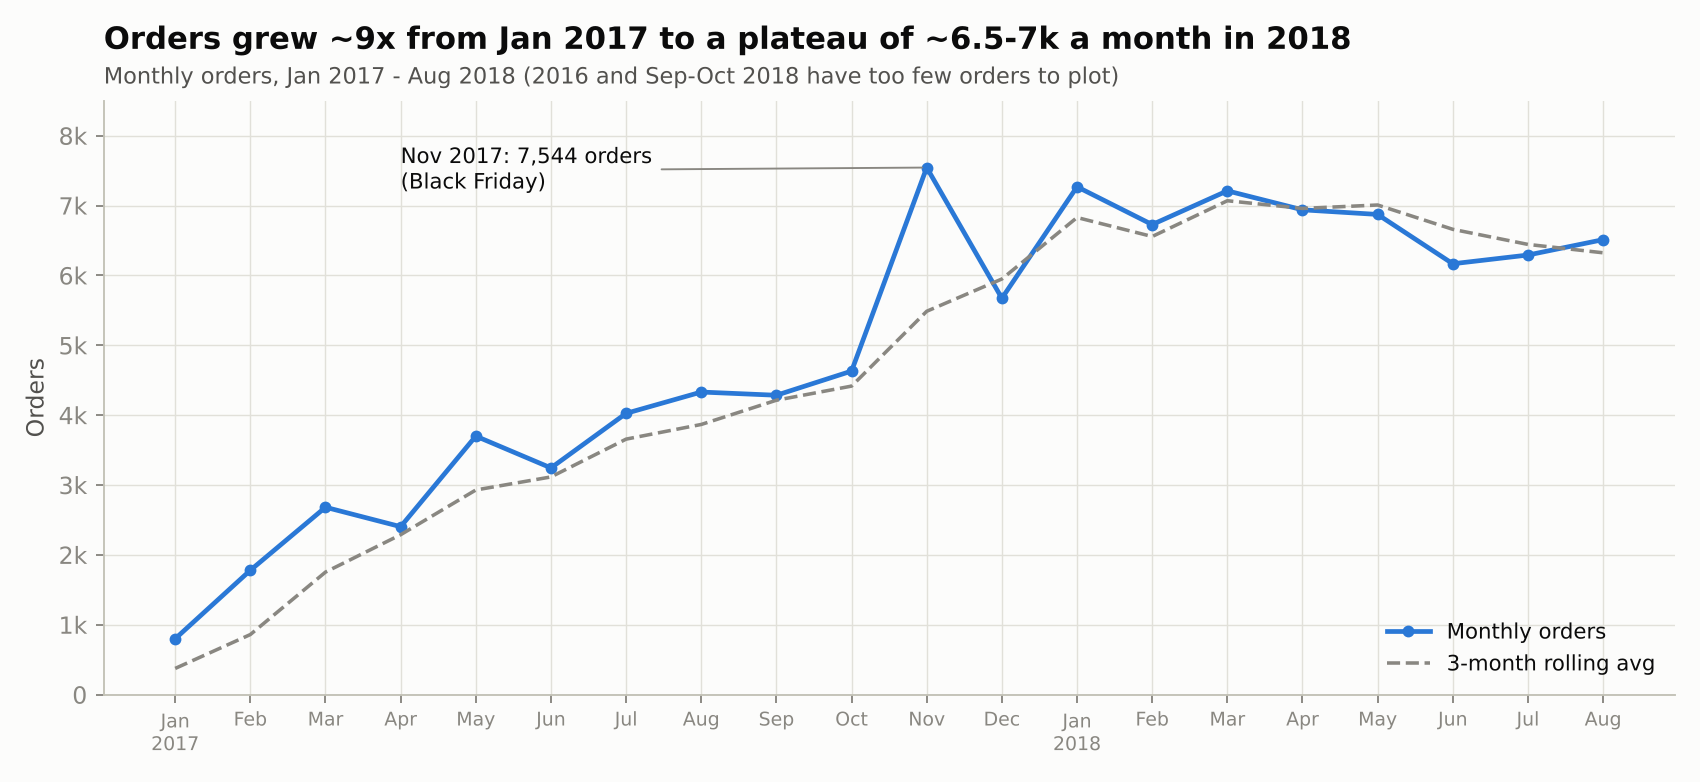

In [9]:
chart('01_monthly_orders_trend.png')

**Insights**
- Yes, there is a strong growth trend. Like-for-like (Jan-Aug), orders grew from 22,968 in 2017 to 53,991 in 2018: +135%.
- Average orders per active month rose from 3,758 in 2017 to 5,401 in 2018 (+44%), even though 2018 lacks the Nov-Dec holiday season.

**Recommendations**
- Use the 2018 run-rate (~6,700 orders a month) as the planning baseline for capacity and inventory, not the 2017 average.

### Q2.2 Is there a growing trend in orders? (month-by-month series)
> Is there a growing trend in the no. of orders placed over the past years? (monthly series with MoM change and 3-month rolling average)

In [10]:
run('2.2')

WITH monthly AS (
  SELECT
    FORMAT_TIMESTAMP('%Y-%m', order_purchase_timestamp) AS order_month,
    COUNT(*) AS total_orders
  FROM target.orders
  GROUP BY order_month
)
SELECT
  order_month,
  total_orders,
  total_orders - LAG(total_orders) OVER (ORDER BY order_month) AS mom_change,
  ROUND(100 * (total_orders - LAG(total_orders) OVER (ORDER BY order_month))
        / NULLIF(LAG(total_orders) OVER (ORDER BY order_month), 0), 2) AS mom_change_pct,
  ROUND(AVG(total_orders) OVER (ORDER BY order_month
        ROWS BETWEEN 2 PRECEDING AND CURRENT ROW), 0) AS rolling_3m_avg
FROM monthly
ORDER BY order_month;

25 rows


,order_month,total_orders,mom_change,mom_change_pct,rolling_3m_avg
0,2016-09,4,<NA>,NaN,4.0
1,2016-10,324,320,8000.00,164.0
2,2016-12,1,-323,-99.69,110.0
3,2017-01,800,799,79900.00,375.0
4,2017-02,1780,980,122.50,860.0
5,2017-03,2682,902,50.67,1754.0
6,2017-04,2404,-278,-10.37,2289.0
7,2017-05,3700,1296,53.91,2929.0
8,2017-06,3245,-455,-12.30,3116.0
9,2017-07,4026,781,24.07,3657.0


**Insights**
- Orders rose almost every month in 2017, from 800 in January to 4,631 in October.
- November 2017 jumped 62.9% month-on-month to 7,544 orders, the all-time peak; 24 Nov 2017 (Black Friday) alone had 1,176 orders, over 5x the average day that month.
- From January 2018 volume plateaued between 6,167 and 7,269 a month: the growth phase is over and the business is now in a scale phase.

**Recommendations**
- Re-ignite growth with acquisition campaigns in under-penetrated states, because organic momentum has flattened since Jan 2018.
- Treat Black Friday as the single largest operational event: pre-book carrier capacity and staff from October.

### Q2.3 Monthly seasonality in the number of orders
> Can we see some kind of monthly seasonality in terms of the no. of orders being placed?

In [11]:
run('2.3')

-- Calendar month on rows, year on columns, so the same month can be compared across years.
SELECT
  EXTRACT(MONTH FROM order_purchase_timestamp) AS month_no,
  SUM(CASE WHEN EXTRACT(YEAR FROM order_purchase_timestamp) = 2016 THEN 1 ELSE 0 END) AS orders_2016,
  SUM(CASE WHEN EXTRACT(YEAR FROM order_purchase_timestamp) = 2017 THEN 1 ELSE 0 END) AS orders_2017,
  SUM(CASE WHEN EXTRACT(YEAR FROM order_purchase_timestamp) = 2018 THEN 1 ELSE 0 END) AS orders_2018,
  COUNT(*) AS total_orders,
  ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_all_orders
FROM target.orders
GROUP BY month_no
ORDER BY month_no;

12 rows


,month_no,orders_2016,orders_2017,orders_2018,total_orders,pct_of_all_orders
0,1,0.0,800.0,7269.0,8069,8.11
1,2,0.0,1780.0,6728.0,8508,8.56
2,3,0.0,2682.0,7211.0,9893,9.95
3,4,0.0,2404.0,6939.0,9343,9.40
4,5,0.0,3700.0,6873.0,10573,10.63
5,6,0.0,3245.0,6167.0,9412,9.46
6,7,0.0,4026.0,6292.0,10318,10.38
7,8,0.0,4331.0,6512.0,10843,10.90
8,9,4.0,4285.0,16.0,4305,4.33
9,10,324.0,4631.0,4.0,4959,4.99


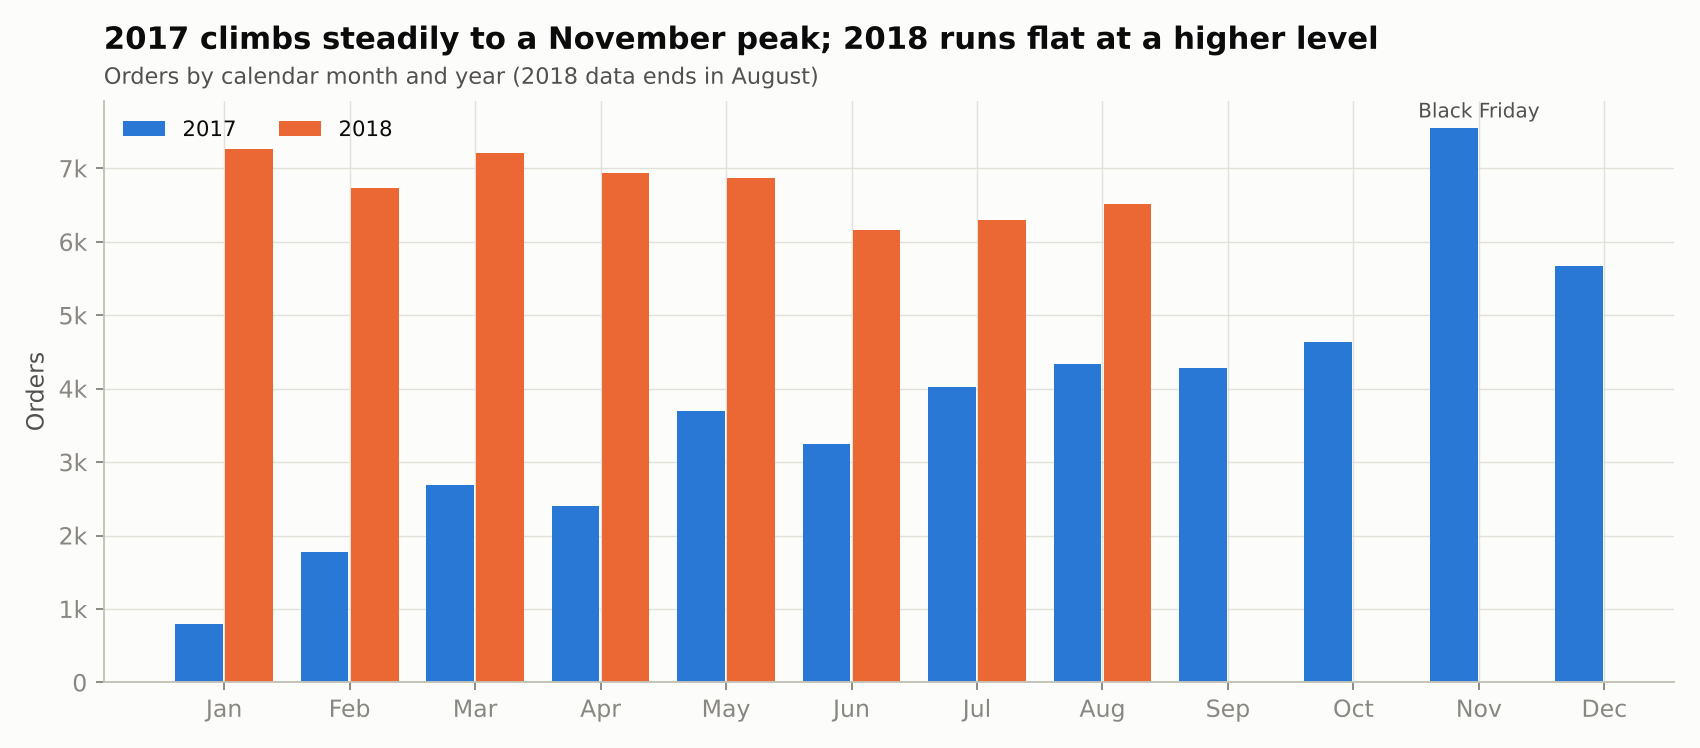

In [12]:
chart('02_monthly_seasonality.png')

**Insights**
- Seasonality exists but is masked by growth. In 2017 orders rose steadily to a November peak (Black Friday) and eased in December.
- In 2018, Jan-Mar were the strongest months (7,269, 6,728, 7,211) and Jun-Jul the weakest (6,167, 6,292): post-holiday and new-year demand are strong, mid-year is soft.
- May, July and August have the highest share of all orders (10.6-10.9%) because they are covered by two full years of data.

**Recommendations**
- Run mid-year (June-July) promotions to fill the seasonal dip.
- Build inventory ahead of November and Q1, the two demand peaks.

### Q2.4 Time of day when Brazilian customers place orders
> During what time of the day do Brazilian customers mostly place their orders? (0-6 Dawn, 7-12 Morning, 13-18 Afternoon, 19-23 Night)

In [13]:
run('2.4')

SELECT
  CASE
    WHEN EXTRACT(HOUR FROM order_purchase_timestamp) BETWEEN 0  AND 6  THEN 'Dawn'
    WHEN EXTRACT(HOUR FROM order_purchase_timestamp) BETWEEN 7  AND 12 THEN 'Morning'
    WHEN EXTRACT(HOUR FROM order_purchase_timestamp) BETWEEN 13 AND 18 THEN 'Afternoon'
    ELSE 'Night'
  END AS time_of_day,
  COUNT(*) AS total_orders,
  ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_orders
FROM target.orders
GROUP BY time_of_day
ORDER BY total_orders DESC;

4 rows


,time_of_day,total_orders,pct_of_orders
0,Afternoon,38135,38.35
1,Night,28331,28.49
2,Morning,27733,27.89
3,Dawn,5242,5.27


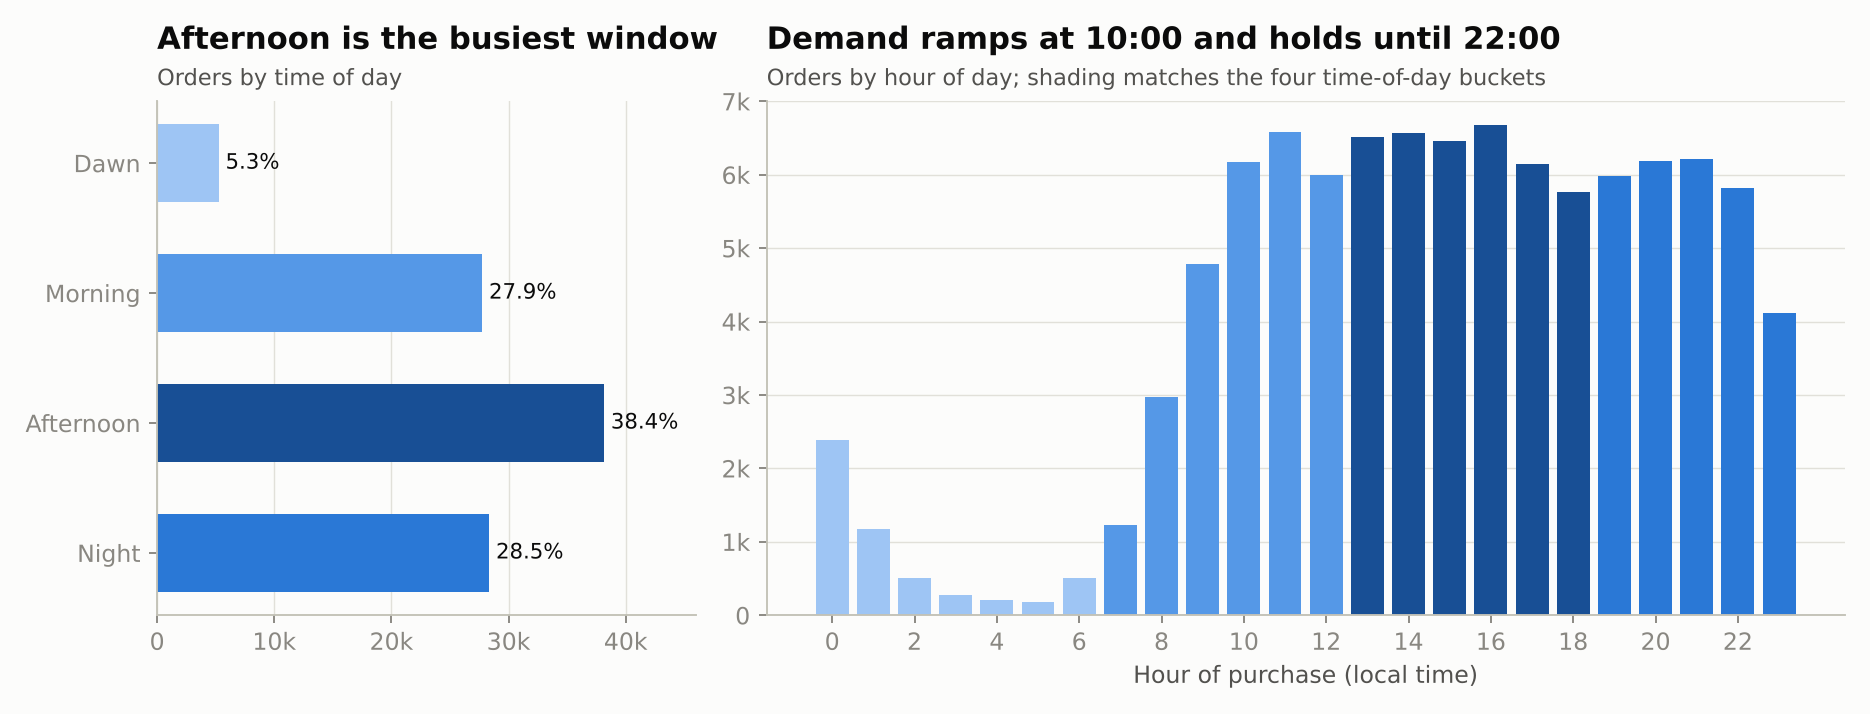

In [14]:
chart('03_time_of_day.png')

**Insights**
- Brazilian customers order mostly in the Afternoon (38.4%), then Night (28.5%) and Morning (27.9%). Dawn is quiet (5.3%).
- By hour, demand ramps from 10:00 and stays high until 22:00; the busiest hour is 16:00 (6,675 orders).

**Recommendations**
- Schedule flash sales, push notifications and paid-media bids for 13:00-22:00.
- Use 0:00-6:00 for site deployments and maintenance, when only 5% of orders arrive.

## 3. Evolution of e-commerce orders in the Brazil region

### Q3.1 Month-on-month number of orders placed in each state
> Get the month on month no. of orders placed in each state.

In [15]:
run('3.1')

WITH state_month AS (
  SELECT
    c.customer_state,
    EXTRACT(YEAR  FROM o.order_purchase_timestamp) AS order_year,
    EXTRACT(MONTH FROM o.order_purchase_timestamp) AS order_month,
    COUNT(o.order_id) AS total_orders
  FROM target.orders AS o
  JOIN target.customers AS c
    ON o.customer_id = c.customer_id
  GROUP BY c.customer_state, order_year, order_month
)
SELECT
  customer_state,
  order_year,
  order_month,
  total_orders,
  total_orders - LAG(total_orders) OVER (
      PARTITION BY customer_state ORDER BY order_year, order_month) AS mom_change
FROM state_month
ORDER BY customer_state, order_year, order_month;



565 rows


,customer_state,order_year,order_month,total_orders,mom_change
0,AC,2017,1,2,<NA>
1,AC,2017,2,3,1
2,AC,2017,3,2,-1
3,AC,2017,4,5,3
4,AC,2017,5,8,3
5,AC,2017,6,4,-4
6,AC,2017,7,5,1
7,AC,2017,8,4,-1
8,AC,2017,9,5,1
9,AC,2017,10,6,1


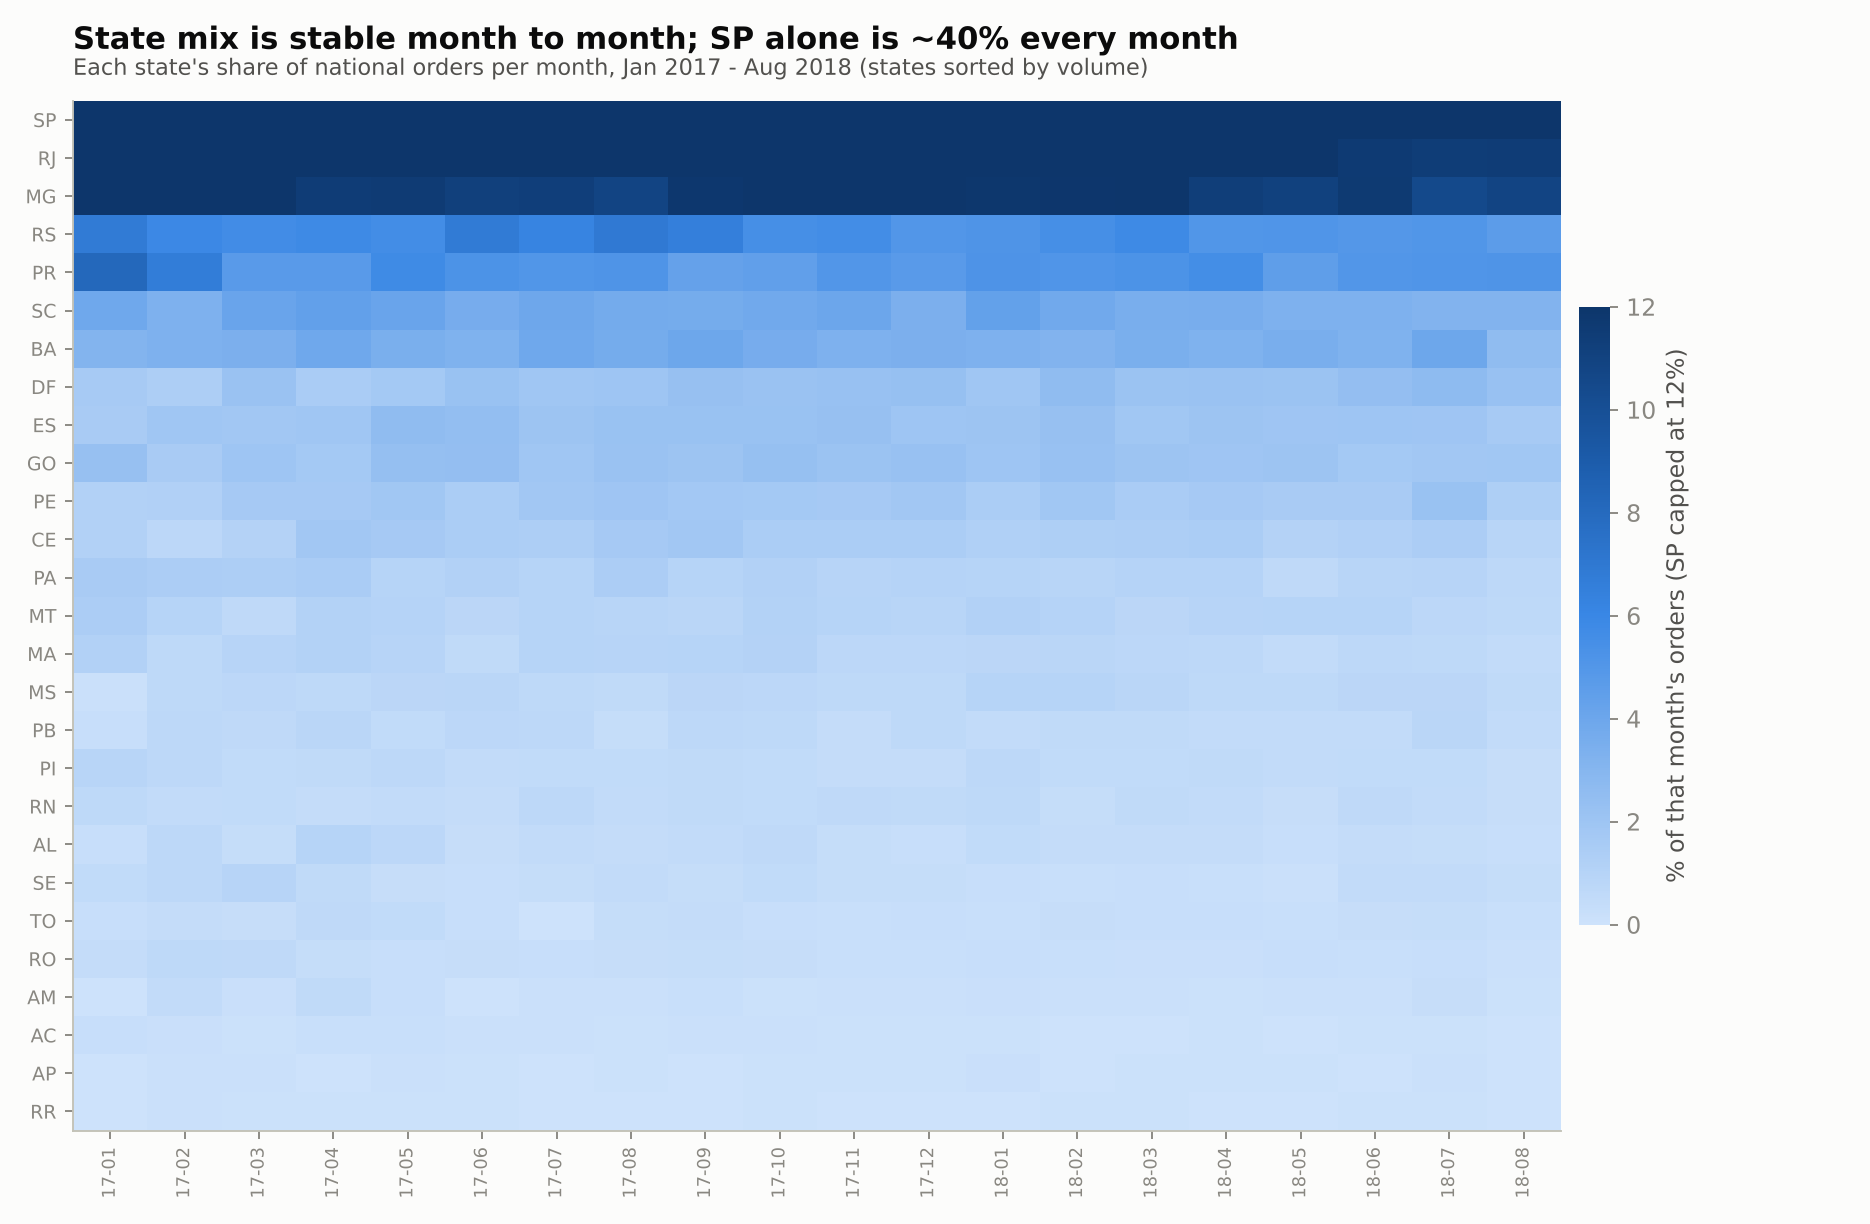

In [16]:
chart('05_state_month_heatmap.png')

**Insights**
- Every state grew between Jan-Aug 2017 and Jan-Aug 2018 except Acre (AC, 33 to 27 orders).
- The fastest growers were DF (+184%), MS (+172%) and SP (+166%). The North and North-East grew slowest: SE (+43%), RO (+35%), AM (+55%), PA (+66%).
- Each state's share of monthly orders is very stable: SP is ~40% every month.

**Recommendations**
- Investigate why the North and North-East lag the national growth rate; delivery time and freight (sections 4-5) are the likely blockers.

### Q3.2 How customers are distributed across states
> How are the customers distributed across all the states?

In [17]:
run('3.2')

WITH by_state AS (
  SELECT
    customer_state,
    COUNT(DISTINCT customer_unique_id) AS unique_customers,
    COUNT(DISTINCT customer_city)      AS cities_covered
  FROM target.customers
  GROUP BY customer_state
)
SELECT
  customer_state,
  unique_customers,
  ROUND(100 * unique_customers / SUM(unique_customers) OVER (), 2) AS pct_of_customers,
  ROUND(100 * SUM(unique_customers) OVER (ORDER BY unique_customers DESC, customer_state
                                          ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW)
        / SUM(unique_customers) OVER (), 2) AS cumulative_pct,
  cities_covered
FROM by_state
ORDER BY unique_customers DESC;



27 rows


,customer_state,unique_customers,pct_of_customers,cumulative_pct,cities_covered
0,SP,40302,41.92,41.92,629
1,RJ,12384,12.88,54.80,149
2,MG,11259,11.71,66.52,745
3,RS,5277,5.49,72.00,379
4,PR,4882,5.08,77.08,364
5,SC,3534,3.68,80.76,240
6,BA,3277,3.41,84.17,353
7,DF,2075,2.16,86.33,6
8,ES,1964,2.04,88.37,95
9,GO,1952,2.03,90.40,178


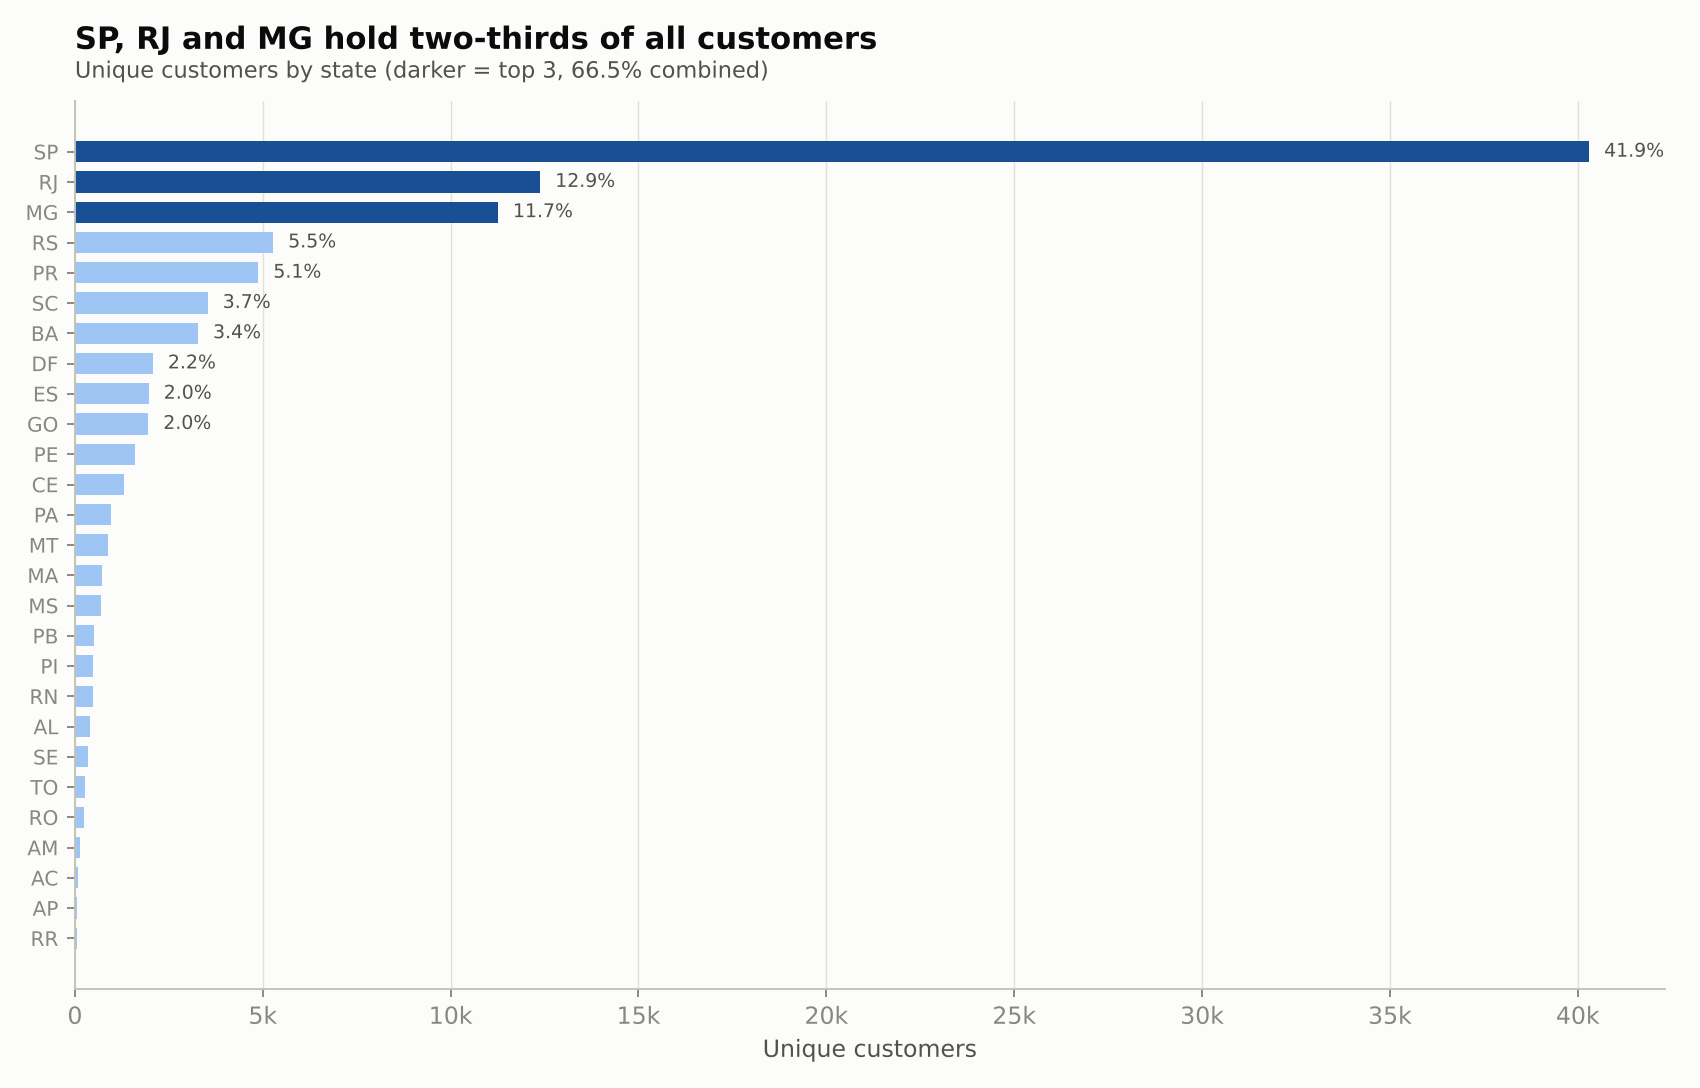

In [18]:
chart('04_customers_by_state.png')

**Insights**
- Customers are highly concentrated: SP has 41.9%, RJ 12.9%, MG 11.7%. The top 5 states (SP, RJ, MG, RS, PR) hold 77.1% of all customers.
- The bottom 5 (RO, AM, AC, AP, RR) together hold only 0.6%. Roraima has just 45 customers.
- SP also covers the most cities in absolute terms after MG (629 vs 745).

**Recommendations**
- Defend the core (SP, RJ, MG) with loyalty programmes; grow the long tail with regional marketing and cheaper shipping, because each new customer there has low competition.

## 4. Impact on economy: money movement

### Q4.1 % increase in cost of orders, 2017 vs 2018 (Jan-Aug)
> Get the % increase in the cost of orders from year 2017 to 2018 (include months between Jan to Aug only), using payment_value.

In [19]:
run('4.1')

WITH yearly_cost AS (
  SELECT
    EXTRACT(YEAR FROM o.order_purchase_timestamp) AS order_year,
    SUM(p.payment_value) AS total_cost
  FROM target.orders AS o
  JOIN target.payments AS p
    ON o.order_id = p.order_id
  WHERE EXTRACT(YEAR  FROM o.order_purchase_timestamp) IN (2017, 2018)
    AND EXTRACT(MONTH FROM o.order_purchase_timestamp) BETWEEN 1 AND 8
  GROUP BY order_year
)
SELECT
  ROUND(MAX(CASE WHEN order_year = 2017 THEN total_cost END), 2) AS cost_2017_jan_aug,
  ROUND(MAX(CASE WHEN order_year = 2018 THEN total_cost END), 2) AS cost_2018_jan_aug,
  ROUND(100 * (MAX(CASE WHEN order_year = 2018 THEN total_cost END)
             - MAX(CASE WHEN order_year = 2017 THEN total_cost END))
        / MAX(CASE WHEN order_year = 2017 THEN total_cost END), 2) AS pct_increase
FROM yearly_cost;



1 rows


,cost_2017_jan_aug,cost_2018_jan_aug,pct_increase
0,3669022.12,8694733.84,136.98


**Insights**
- The cost of orders (payment_value) grew from R$3.67M in Jan-Aug 2017 to R$8.69M in Jan-Aug 2018, an increase of 136.98%.
- Average order value was flat (R$159.7 vs R$161.0), so the increase comes from more orders, not higher prices.

**Recommendations**
- Add basket-building levers (bundles, free-shipping thresholds, cross-sell) to grow order value now that volume growth has slowed.

### Q4.2 Cost of orders by month, 2017 vs 2018 (Jan-Aug)
> Supporting view for 4.1: where in the year did the growth come from?

In [20]:
run('4.2')

SELECT
  EXTRACT(MONTH FROM o.order_purchase_timestamp) AS month_no,
  ROUND(SUM(CASE WHEN EXTRACT(YEAR FROM o.order_purchase_timestamp) = 2017 THEN p.payment_value END), 2) AS cost_2017,
  ROUND(SUM(CASE WHEN EXTRACT(YEAR FROM o.order_purchase_timestamp) = 2018 THEN p.payment_value END), 2) AS cost_2018,
  ROUND(100 * (SUM(CASE WHEN EXTRACT(YEAR FROM o.order_purchase_timestamp) = 2018 THEN p.payment_value END)
             - SUM(CASE WHEN EXTRACT(YEAR FROM o.order_purchase_timestamp) = 2017 THEN p.payment_value END))
        / SUM(CASE WHEN EXTRACT(YEAR FROM o.order_purchase_timestamp) = 2017 THEN p.payment_value END), 2) AS yoy_pct
FROM target.orders AS o
JOIN target.payments AS p
  ON o.order_id = p.order_id
WHERE EXTRACT(MONTH FROM o.order_purchase_timestamp) BETWEEN 1 AND 8
GROUP BY month_no
ORDER BY month_no;



8 rows


,month_no,cost_2017,cost_2018,yoy_pct
0,1,138488.04,1115004.18,705.13
1,2,291908.01,992463.34,239.99
2,3,449863.60,1159652.12,157.78
3,4,417788.03,1160785.48,177.84
4,5,592918.82,1153982.15,94.63
5,6,511276.38,1023880.50,100.26
6,7,592382.92,1066540.75,80.04
7,8,674396.32,1022425.32,51.61


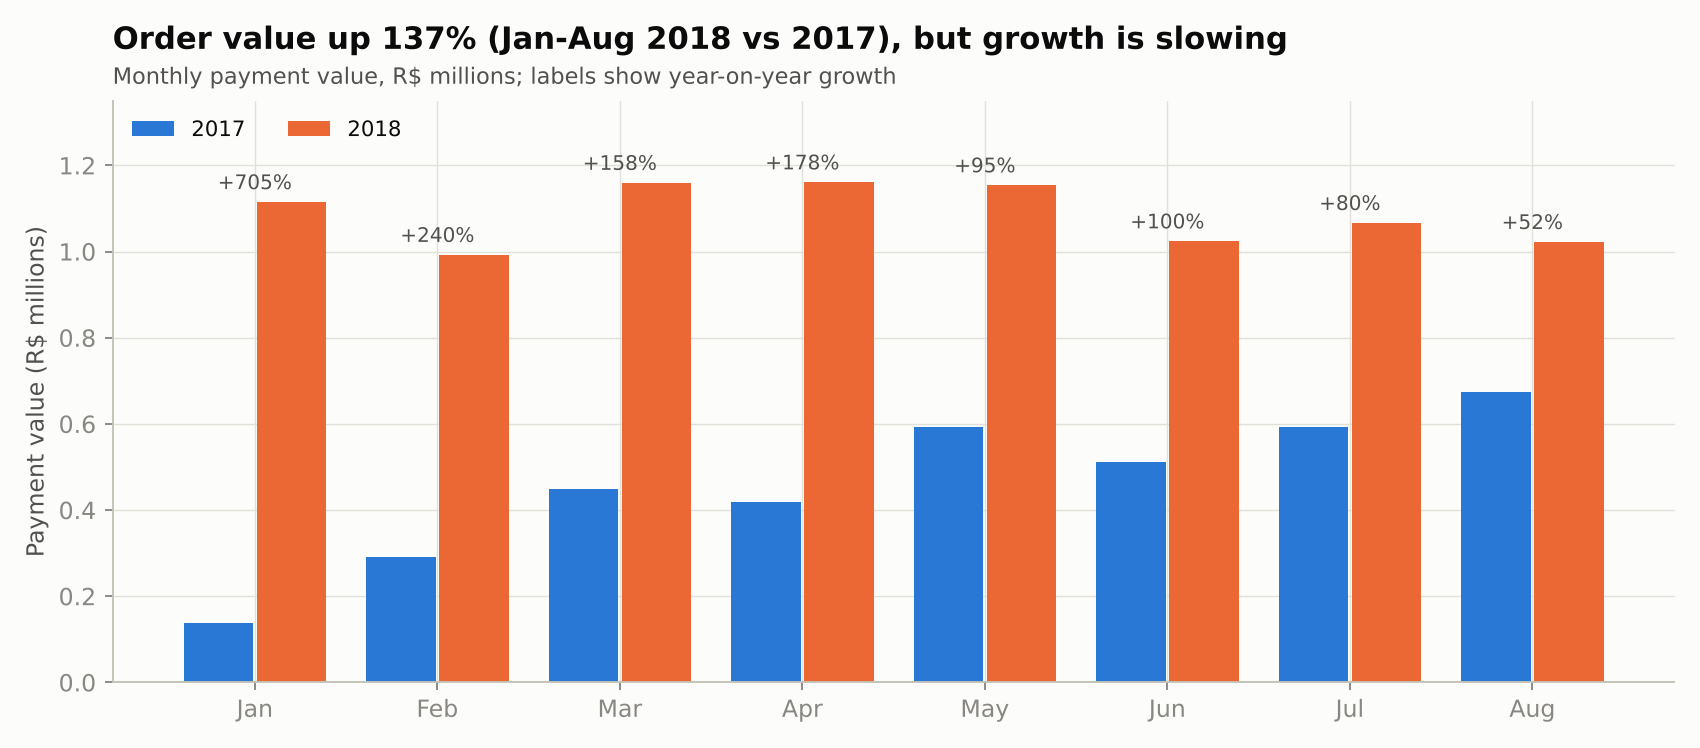

In [21]:
chart('06_cost_growth_2017_2018.png')

**Insights**
- Year-on-year growth decays month by month: +705% in January, +178% in April, +52% in August.
- 2018 monthly value is flat at R$1.0-1.16M, confirming the plateau seen in order counts.

**Recommendations**
- Set 2019 targets on a plateau-aware baseline; extrapolating early-2018 growth rates would overstate demand by a wide margin.

### Q4.3 Total & average order price for each state
> Calculate the Total & Average value of order price for each state.

In [22]:
run('4.3')

SELECT
  c.customer_state,
  ROUND(SUM(oi.price), 2) AS total_order_price,
  ROUND(AVG(oi.price), 2) AS avg_price_per_item,
  ROUND(SUM(oi.price) / COUNT(DISTINCT oi.order_id), 2) AS avg_price_per_order,
  COUNT(DISTINCT oi.order_id) AS orders
FROM target.orders AS o
JOIN target.customers   AS c  ON o.customer_id = c.customer_id
JOIN target.order_items AS oi ON o.order_id = oi.order_id
GROUP BY c.customer_state
ORDER BY total_order_price DESC;



27 rows


,customer_state,total_order_price,avg_price_per_item,avg_price_per_order,orders
0,SP,5202955.05,109.65,125.75,41375
1,RJ,1824092.67,125.12,142.93,12762
2,MG,1585308.03,120.75,137.33,11544
3,RS,750304.02,120.34,138.13,5432
4,PR,683083.76,119.00,136.67,4998
5,SC,520553.34,124.65,144.12,3612
6,BA,511349.99,134.60,152.28,3358
7,DF,302603.94,125.77,142.40,2125
8,GO,294591.95,126.27,146.78,2007
9,ES,275037.31,121.91,135.82,2025


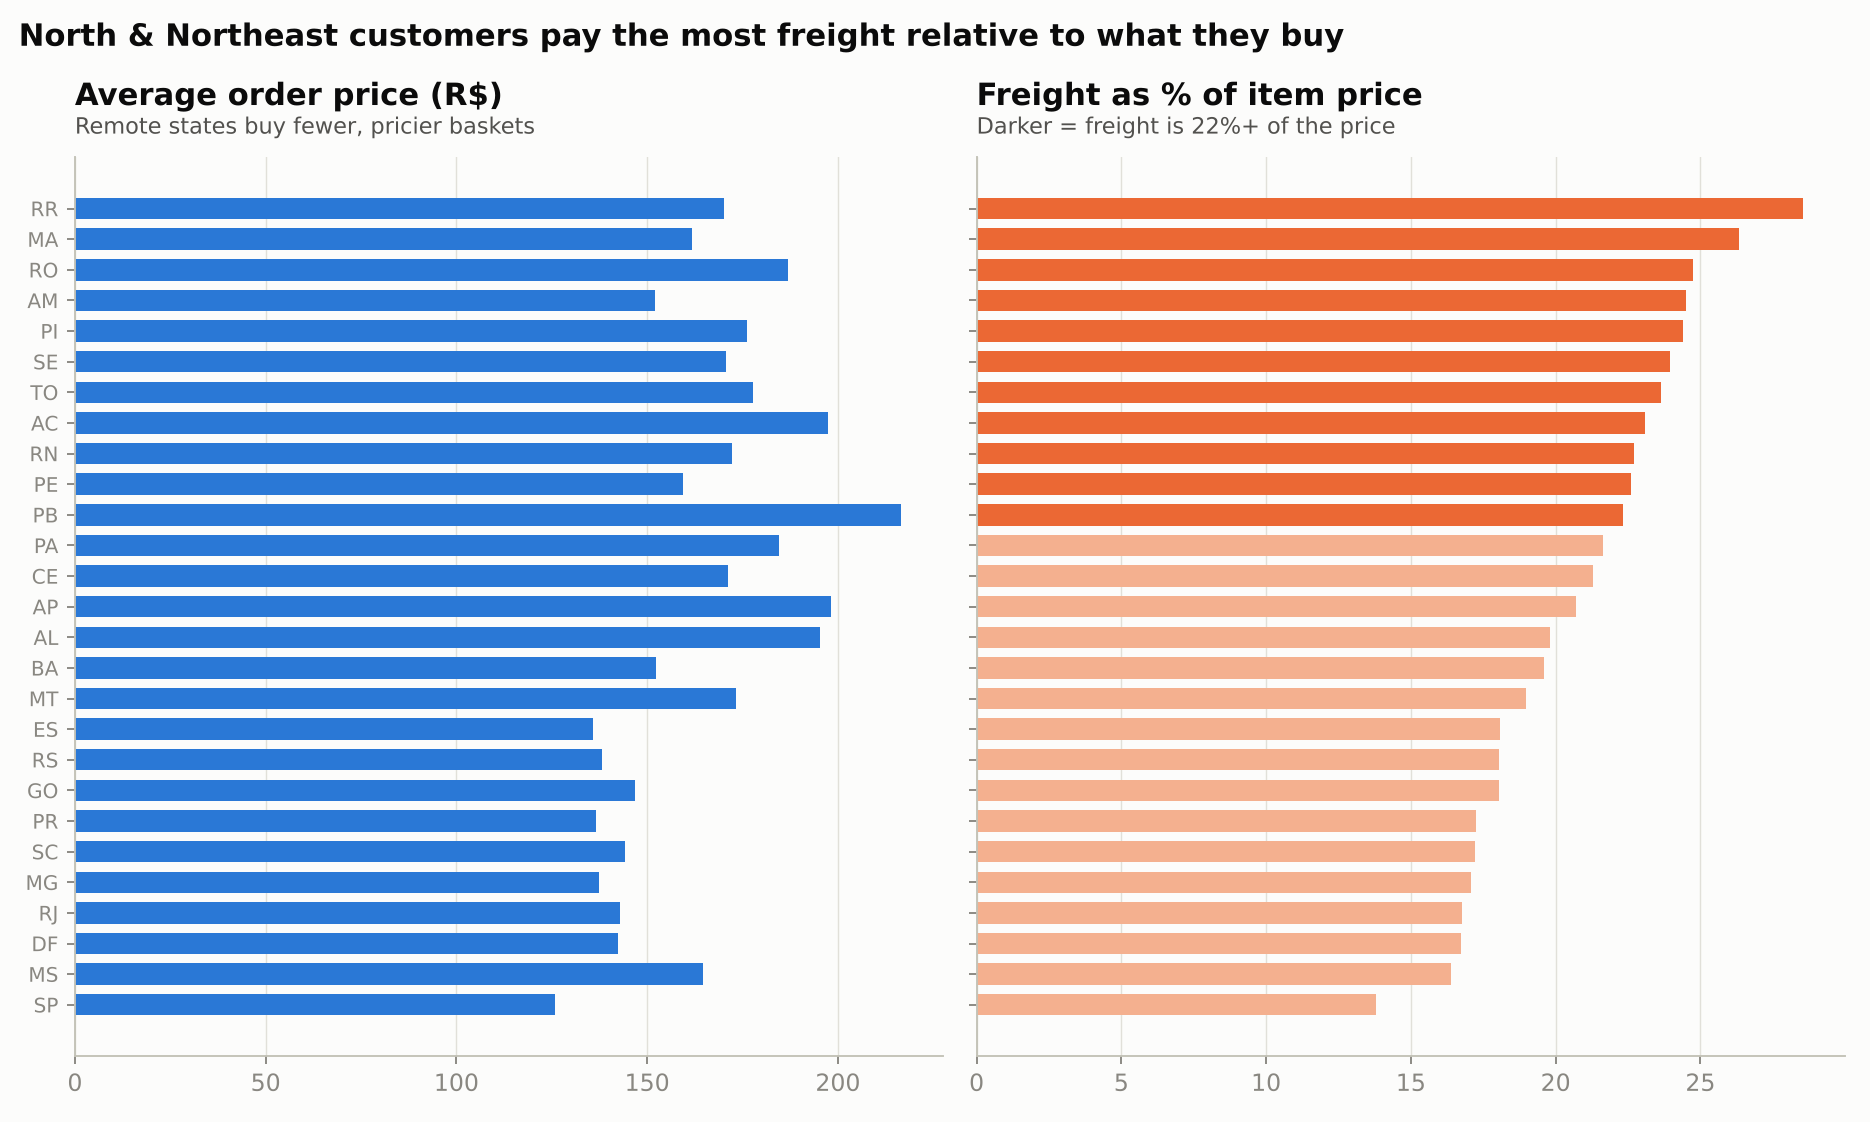

In [23]:
chart('07_price_vs_freight_by_state.png')

**Insights**
- SP generates the most revenue by far (R$5.20M, 38% of item value), followed by RJ (R$1.82M) and MG (R$1.59M).
- SP also has the lowest average order price (R$125.75 per order). Remote states buy fewer but pricier baskets: PB R$216.67, AP R$198.15, AC R$197.32 per order.

**Recommendations**
- In remote states, customers only buy when the item is valuable enough to justify the shipping. Lower freight would unlock everyday, lower-priced purchases there.

### Q4.4 Total & average freight value for each state
> Calculate the Total & Average value of order freight for each state.

In [24]:
run('4.4')

SELECT
  c.customer_state,
  ROUND(SUM(oi.freight_value), 2) AS total_freight_value,
  ROUND(AVG(oi.freight_value), 2) AS avg_freight_per_item,
  ROUND(SUM(oi.freight_value) / COUNT(DISTINCT oi.order_id), 2) AS avg_freight_per_order,
  ROUND(100 * SUM(oi.freight_value) / SUM(oi.price), 2) AS freight_as_pct_of_price
FROM target.orders AS o
JOIN target.customers   AS c  ON o.customer_id = c.customer_id
JOIN target.order_items AS oi ON o.order_id = oi.order_id
GROUP BY c.customer_state
ORDER BY total_freight_value DESC;



27 rows


,customer_state,total_freight_value,avg_freight_per_item,avg_freight_per_order,freight_as_pct_of_price
0,SP,718723.07,15.15,17.37,13.81
1,RJ,305589.31,20.96,23.95,16.75
2,MG,270853.46,20.63,23.46,17.09
3,RS,135522.74,21.74,24.95,18.06
4,PR,117851.68,20.53,23.58,17.25
5,BA,100156.68,26.36,29.83,19.59
6,SC,89660.26,21.47,24.82,17.22
7,PE,59449.66,32.92,36.07,22.62
8,GO,53114.98,22.77,26.46,18.03
9,DF,50625.50,21.04,23.82,16.73


**Insights**
- Total freight is largest in SP (R$718.7K) because of volume, but SP's average freight per item is the lowest (R$15.15).
- Freight is a much heavier burden in the North and North-East: 28.6% of the item price in RR, 26.4% in MA and 24.7% in RO, vs 13.8% in SP.

**Recommendations**
- Introduce regional freight subsidies or free-shipping thresholds for states where freight exceeds 20% of the price.

## 5. Sales, freight & delivery time

### Q5.1 Delivery time and estimated-vs-actual gap per order (single query)
> Find the no. of days taken to deliver each order from the purchase date (time_to_deliver) and the difference in days between the actual & estimated delivery date (diff_estimated_delivery), in a single query.

In [25]:
run('5.1')

-- time_to_deliver         = order_delivered_customer_date - order_purchase_timestamp
-- diff_estimated_delivery = order_delivered_customer_date - order_estimated_delivery_date
--   (negative = delivered BEFORE the estimate, positive = days late;
--    an order counts as late throughout this study when diff_estimated_delivery > 0)
SELECT
  order_id,
  order_purchase_timestamp,
  order_delivered_customer_date,
  order_estimated_delivery_date,
  TIMESTAMP_DIFF(order_delivered_customer_date, order_purchase_timestamp, DAY)      AS time_to_deliver,
  TIMESTAMP_DIFF(order_delivered_customer_date, order_estimated_delivery_date, DAY) AS diff_estimated_delivery
FROM target.orders
WHERE order_status = 'delivered'
  AND order_delivered_customer_date IS NOT NULL
ORDER BY order_purchase_timestamp;



96,470 rows


,order_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,time_to_deliver,diff_estimated_delivery
0,bfbd0f9bdef84302105ad712db648a6c,2016-09-15 12:16:38,2016-11-09 07:47:38,2016-10-04,54,36
1,3b697a20d9e427646d92567910af6d57,2016-10-03 09:44:50,2016-10-26 14:02:13,2016-10-27,23,0
2,be5bc2f0da14d8071e2d45451ad119d9,2016-10-03 16:56:50,2016-10-27 18:19:38,2016-11-07,24,-10
3,a41c8759fbe7aab36ea07e038b2d4465,2016-10-03 21:13:36,2016-11-03 10:58:07,2016-11-29,30,-25
4,d207cc272675637bfed0062edffd0818,2016-10-03 22:06:03,2016-10-31 11:07:42,2016-11-23,27,-22
5,cd3b8574c82b42fc8129f6d502690c3e,2016-10-03 22:31:31,2016-10-14 16:08:00,2016-11-23,10,-39
6,ae8a60e4b03c5a4ba9ca0672c164b181,2016-10-03 22:44:10,2016-11-03 14:04:50,2016-12-01,30,-27
7,ef1b29b591d31d57c0d7337460dd83c9,2016-10-03 22:51:30,2016-11-01 15:14:45,2016-11-25,28,-23
8,0a0837a5eee9e7a9ce2b1fa831944d27,2016-10-04 09:06:10,2016-10-22 14:51:18,2016-11-24,18,-32
9,1ff217aa612f6cd7c4255c9bfe931c8b,2016-10-04 09:16:33,2016-10-24 16:33:45,2016-11-24,20,-30


**Insights**
- The query returns one row per delivered order (96,470 rows) with time_to_deliver and diff_estimated_delivery, computed exactly as the brief's formulas.
- A negative diff_estimated_delivery means the order arrived before the estimate; the first rows show typical values of -22 to -39 days in late 2016.

**Recommendations**
- Store both metrics in a delivery fact table so operations can track them daily.

### Q5.2 Delivery performance summary (supporting 5.1)
> Supporting view: overall distribution of delivery time and lateness.

In [26]:
run('5.2')

WITH d AS (
  SELECT
    TIMESTAMP_DIFF(order_delivered_customer_date, order_purchase_timestamp, DAY)      AS time_to_deliver,
    TIMESTAMP_DIFF(order_delivered_customer_date, order_estimated_delivery_date, DAY) AS diff_estimated_delivery
  FROM target.orders
  WHERE order_status = 'delivered'
    AND order_delivered_customer_date IS NOT NULL
)
SELECT
  COUNT(*) AS delivered_orders,
  ROUND(AVG(time_to_deliver), 2) AS avg_days_to_deliver,
  MIN(time_to_deliver) AS min_days,
  MAX(time_to_deliver) AS max_days,
  ROUND(AVG(diff_estimated_delivery), 2) AS avg_days_vs_estimate,
  SUM(CASE WHEN diff_estimated_delivery > 0 THEN 1 ELSE 0 END) AS late_orders,
  ROUND(100 * SUM(CASE WHEN diff_estimated_delivery > 0 THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_late
FROM d;

1 rows


,delivered_orders,avg_days_to_deliver,min_days,max_days,avg_days_vs_estimate,late_orders,pct_late
0,96470,12.09,0,209,-10.96,6534.0,6.77


**Insights**
- Average delivery time is 12.09 days (0 to 209 days).
- On average orders arrive 10.96 days before the estimate, yet 6,534 orders (6.77%) still arrive at least one day late.
- SP (1,820) and RJ (1,495) account for 50.7% of late orders.

**Recommendations**
- Estimates are padded by ~11 days. Tightening them would make the site more competitive at checkout without changing logistics.

### Q5.3 Top 5 states with the highest & lowest average freight value
> Find out the top 5 states with the highest & lowest average freight value.

In [27]:
run('5.3')

WITH state_freight AS (
  SELECT
    c.customer_state,
    ROUND(AVG(oi.freight_value), 2) AS avg_freight_value
  FROM target.orders AS o
  JOIN target.customers   AS c  ON o.customer_id = c.customer_id
  JOIN target.order_items AS oi ON o.order_id = oi.order_id
  GROUP BY c.customer_state
),
ranked AS (
  SELECT
    customer_state,
    avg_freight_value,
    ROW_NUMBER() OVER (ORDER BY avg_freight_value DESC) AS rank_high,
    ROW_NUMBER() OVER (ORDER BY avg_freight_value ASC)  AS rank_low
  FROM state_freight
)
SELECT
  h.rank_high          AS rank_no,
  h.customer_state     AS highest_freight_state,
  h.avg_freight_value  AS highest_avg_freight,
  l.customer_state     AS lowest_freight_state,
  l.avg_freight_value  AS lowest_avg_freight
FROM ranked AS h
JOIN ranked AS l
  ON h.rank_high = l.rank_low
WHERE h.rank_high <= 5
ORDER BY rank_no;



5 rows


,rank_no,highest_freight_state,highest_avg_freight,lowest_freight_state,lowest_avg_freight
0,1,RR,42.98,SP,15.15
1,2,PB,42.72,PR,20.53
2,3,RO,41.07,MG,20.63
3,4,AC,40.07,RJ,20.96
4,5,PI,39.15,DF,21.04


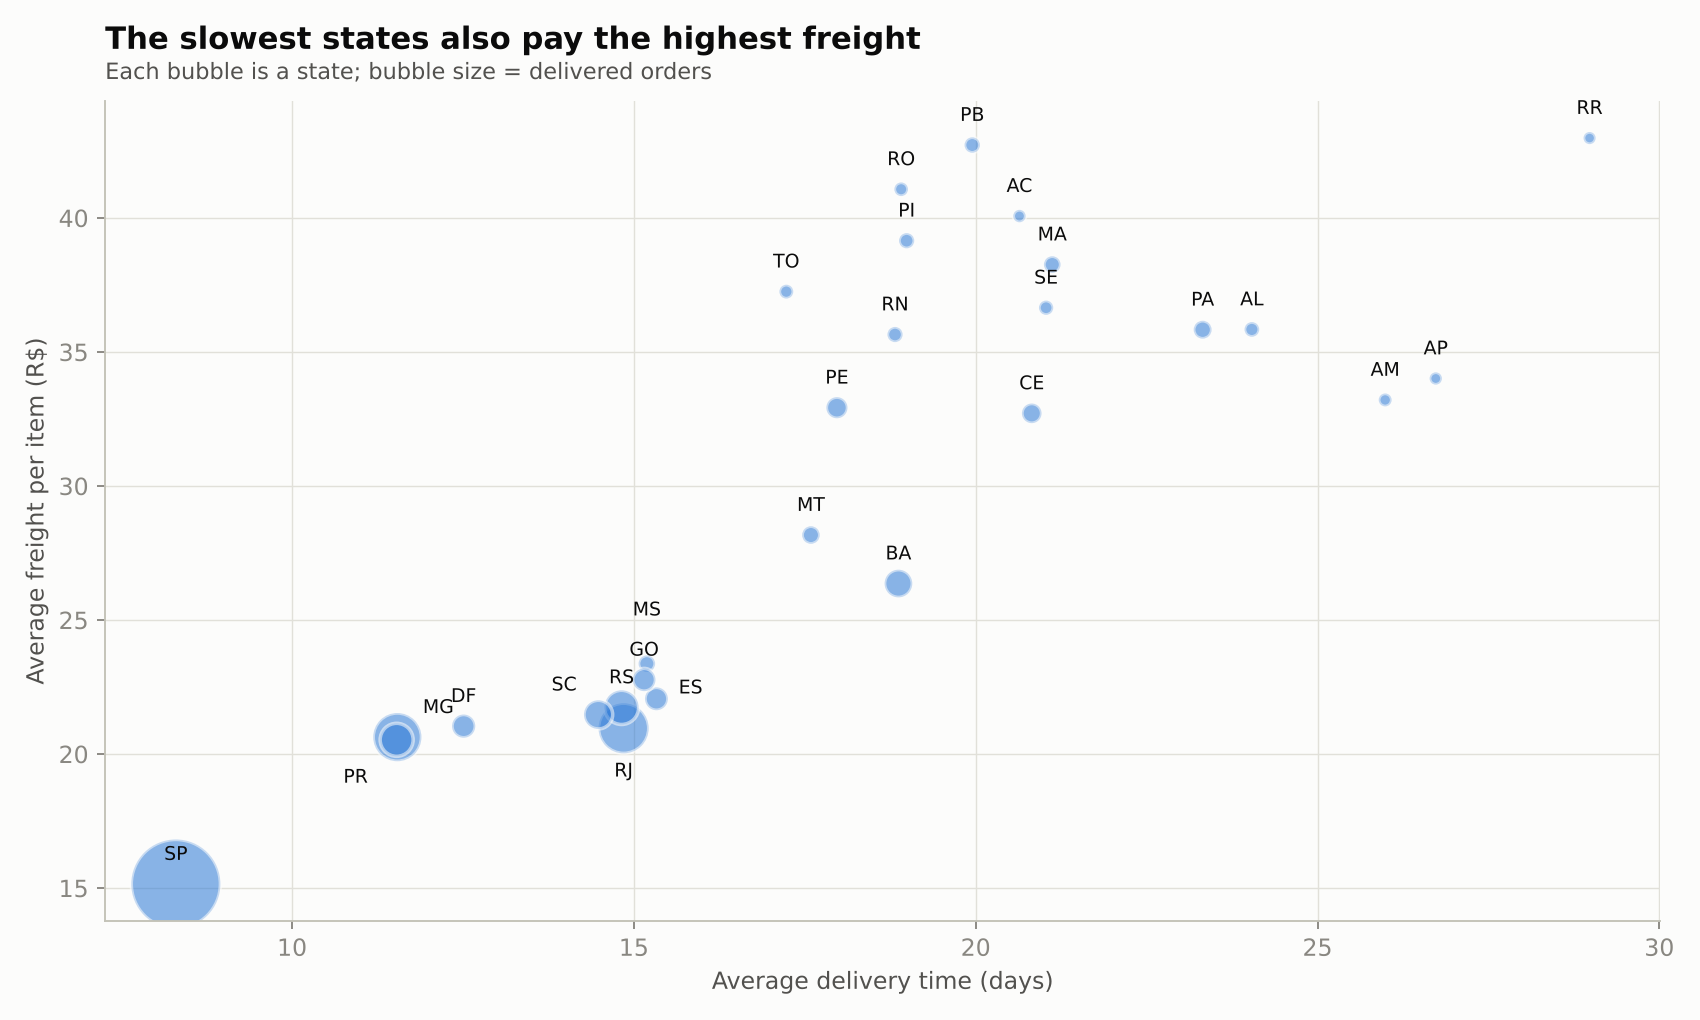

In [28]:
chart('09_freight_vs_delivery_by_state.png')

**Insights**
- Highest average freight: RR (R$42.98), PB (R$42.72), RO (R$41.07), AC (R$40.07), PI (R$39.15), all North/North-East states far from the SP hub.
- Lowest: SP (R$15.15), PR (R$20.53), MG (R$20.63), RJ (R$20.96), DF (R$21.04), the states with the most orders and sellers.
- Freight in RR is 2.8x that in SP.

**Recommendations**
- Negotiate consolidated (bulk) shipping contracts for the North and North-East, and open a regional cross-dock to shorten the line-haul.

### Q5.4 Top 5 states with the highest & lowest average delivery time
> Find out the top 5 states with the highest & lowest average delivery time.

In [29]:
run('5.4')

WITH state_delivery AS (
  SELECT
    c.customer_state,
    ROUND(AVG(TIMESTAMP_DIFF(o.order_delivered_customer_date, o.order_purchase_timestamp, DAY)), 2)
      AS avg_delivery_days
  FROM target.orders AS o
  JOIN target.customers AS c ON o.customer_id = c.customer_id
  WHERE o.order_status = 'delivered'
    AND o.order_delivered_customer_date IS NOT NULL
  GROUP BY c.customer_state
),
ranked AS (
  SELECT
    customer_state,
    avg_delivery_days,
    ROW_NUMBER() OVER (ORDER BY avg_delivery_days DESC) AS rank_slow,
    ROW_NUMBER() OVER (ORDER BY avg_delivery_days ASC)  AS rank_fast
  FROM state_delivery
)
SELECT
  s.rank_slow          AS rank_no,
  s.customer_state     AS slowest_state,
  s.avg_delivery_days  AS slowest_avg_days,
  f.customer_state     AS fastest_state,
  f.avg_delivery_days  AS fastest_avg_days
FROM ranked AS s
JOIN ranked AS f
  ON s.rank_slow = f.rank_fast
WHERE s.rank_slow <= 5
ORDER BY rank_no;



5 rows


,rank_no,slowest_state,slowest_avg_days,fastest_state,fastest_avg_days
0,1,RR,28.98,SP,8.30
1,2,AP,26.73,PR,11.53
2,3,AM,25.99,MG,11.54
3,4,AL,24.04,DF,12.51
4,5,PA,23.32,SC,14.48


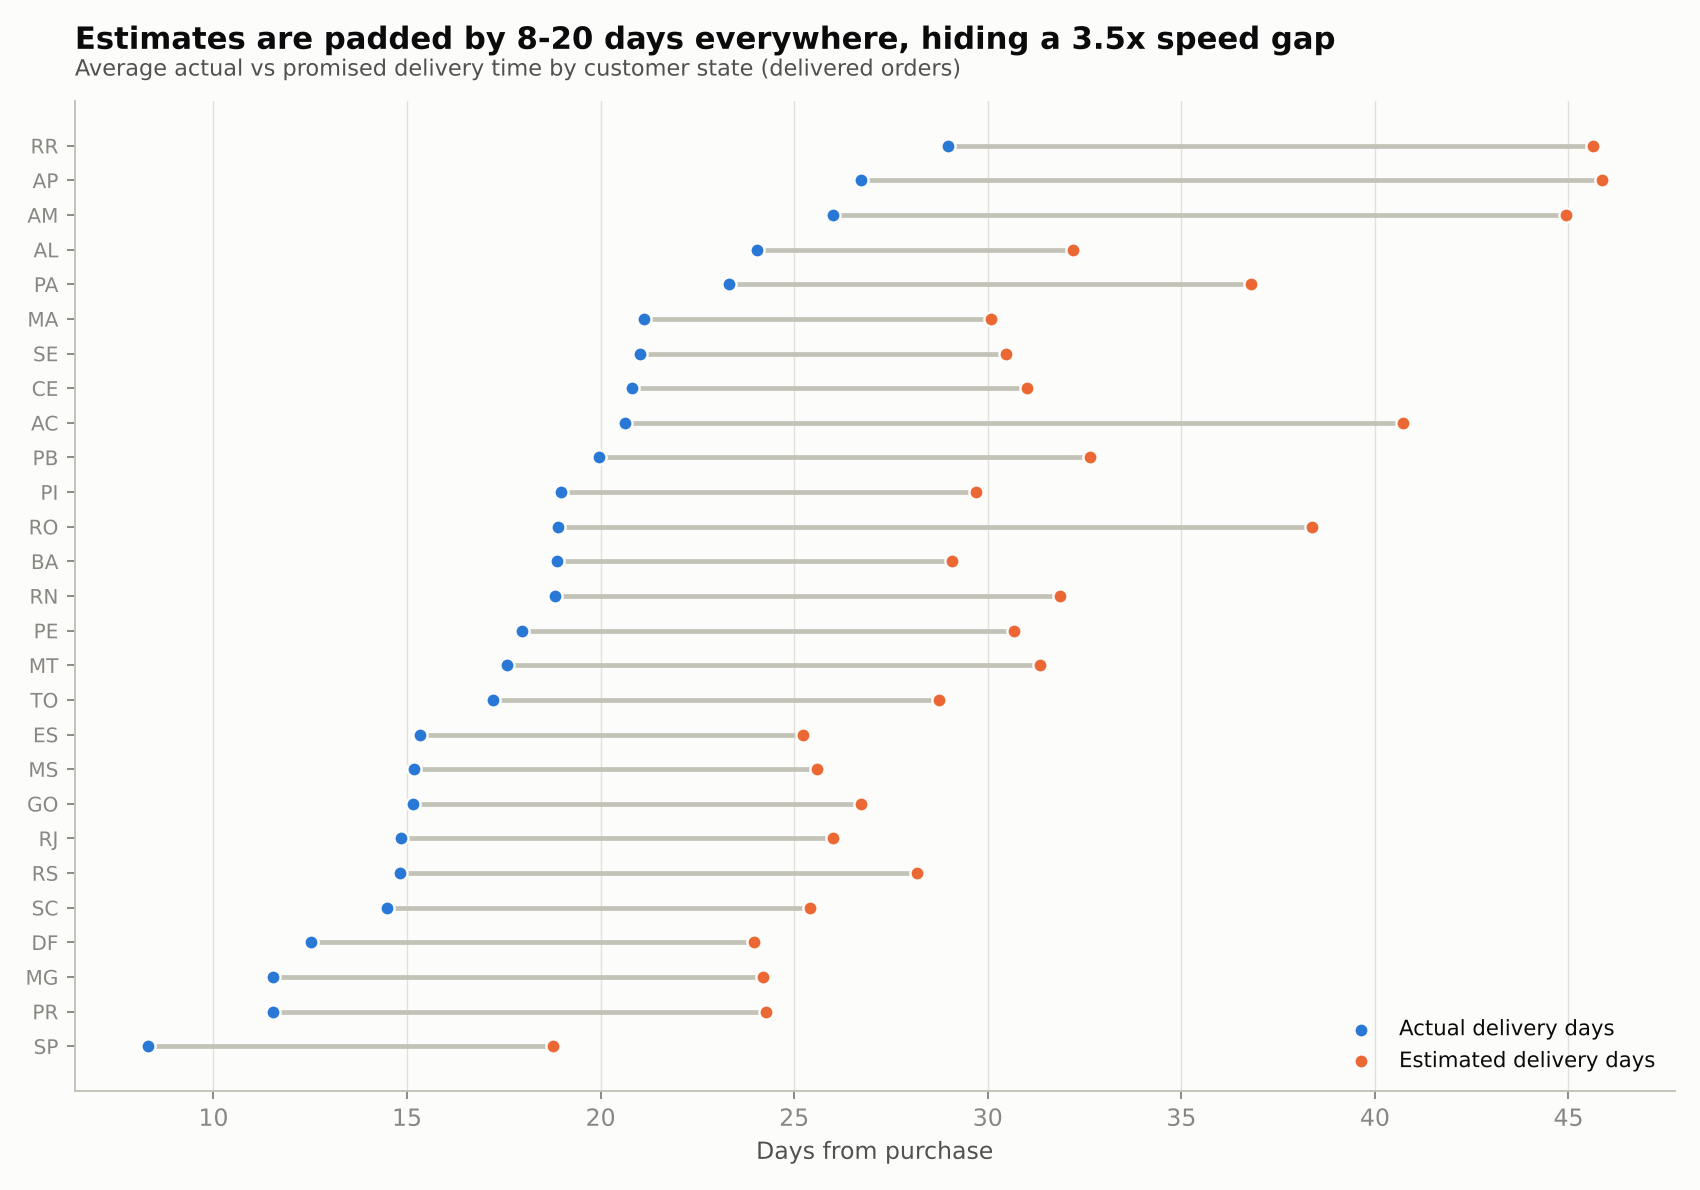

In [30]:
chart('08_delivery_actual_vs_estimate.png')

**Insights**
- Slowest deliveries: RR (29.0 days), AP (26.7), AM (26.0), AL (24.0), PA (23.3).
- Fastest: SP (8.3 days), PR (11.5), MG (11.5), DF (12.5), SC (14.5).
- A customer in Roraima waits 3.5x longer than one in São Paulo.

**Recommendations**
- Recruit sellers or place inventory in the North and North-East; same-state orders arrive in half the time (see 7.2).

### Q5.5 Top 5 states where delivery is fastest compared to the estimate
> Find out the top 5 states where the order delivery is really fast as compared to the estimated date of delivery (difference between the averages of actual & estimated delivery time).

In [31]:
run('5.5')

WITH d AS (
  SELECT
    c.customer_state,
    TIMESTAMP_DIFF(o.order_delivered_customer_date, o.order_purchase_timestamp, DAY)     AS actual_days,
    TIMESTAMP_DIFF(o.order_estimated_delivery_date, o.order_purchase_timestamp, DAY)     AS estimated_days,
    CASE WHEN TIMESTAMP_DIFF(o.order_delivered_customer_date, o.order_estimated_delivery_date, DAY) > 0 THEN 1 ELSE 0 END AS is_late
  FROM target.orders AS o
  JOIN target.customers AS c ON o.customer_id = c.customer_id
  WHERE o.order_status = 'delivered'
    AND o.order_delivered_customer_date IS NOT NULL
)
SELECT
  customer_state,
  ROUND(AVG(actual_days), 2)    AS avg_actual_days,
  ROUND(AVG(estimated_days), 2) AS avg_estimated_days,
  ROUND(AVG(estimated_days) - AVG(actual_days), 2) AS days_faster_than_estimate,
  ROUND(100 * AVG(is_late), 2)  AS pct_late
FROM d
GROUP BY customer_state
ORDER BY days_faster_than_estimate DESC
LIMIT 5;

5 rows


,customer_state,avg_actual_days,avg_estimated_days,days_faster_than_estimate,pct_late
0,AC,20.64,40.73,20.09,3.75
1,RO,18.91,38.39,19.47,2.88
2,AP,26.73,45.87,19.13,2.99
3,AM,25.99,44.92,18.94,2.76
4,RR,28.98,45.63,16.66,12.20


**Insights**
- Deliveries beat the estimate by the widest margin in AC (20.1 days early), RO (19.5), AP (19.1), AM (18.9) and RR (16.7).
- These are the slowest states. They look 'fast' only because their estimates are padded to 38-46 days.
- By contrast, AL (23.9% late) and MA (19.7% late) have the least reliable estimates.

**Recommendations**
- Recalibrate estimates per state. Over-promising by 20 days loses sales at checkout; under-promising in AL and MA damages reviews.

### Q5.6 State delivery scorecard (all 27 states)
> Supporting view: delivery speed, buffer vs estimate, lateness and freight side by side for every state.

In [32]:
run('5.6')

WITH d AS (
  SELECT
    c.customer_state,
    o.order_id,
    TIMESTAMP_DIFF(o.order_delivered_customer_date, o.order_purchase_timestamp, DAY) AS actual_days,
    TIMESTAMP_DIFF(o.order_estimated_delivery_date, o.order_purchase_timestamp, DAY) AS estimated_days,
    CASE WHEN TIMESTAMP_DIFF(o.order_delivered_customer_date, o.order_estimated_delivery_date, DAY) > 0 THEN 1 ELSE 0 END AS is_late
  FROM target.orders AS o
  JOIN target.customers AS c ON o.customer_id = c.customer_id
  WHERE o.order_status = 'delivered'
    AND o.order_delivered_customer_date IS NOT NULL
),
f AS (
  SELECT c.customer_state, AVG(oi.freight_value) AS avg_freight
  FROM target.orders AS o
  JOIN target.customers   AS c  ON o.customer_id = c.customer_id
  JOIN target.order_items AS oi ON o.order_id = oi.order_id
  GROUP BY c.customer_state
)
SELECT
  d.customer_state,
  COUNT(*) AS delivered_orders,
  ROUND(AVG(d.actual_days), 2) AS avg_actual_days,
  ROUND(AVG(d.estimated_days) - AVG(d.actual_days), 2) AS day

27 rows


,customer_state,delivered_orders,avg_actual_days,days_faster_than_estimate,pct_late,avg_freight_per_item
0,RR,41,28.98,16.66,12.20,42.98
1,AP,67,26.73,19.13,2.99,34.01
2,AM,145,25.99,18.94,2.76,33.21
3,AL,397,24.04,8.17,21.41,35.84
4,PA,946,23.32,13.48,11.21,35.83
5,MA,717,21.12,8.97,17.43,38.26
6,SE,335,21.03,9.45,15.22,36.65
7,CE,1279,20.82,10.19,13.76,32.71
8,AC,80,20.64,20.09,3.75,40.07
9,PB,517,19.95,12.70,10.44,42.72


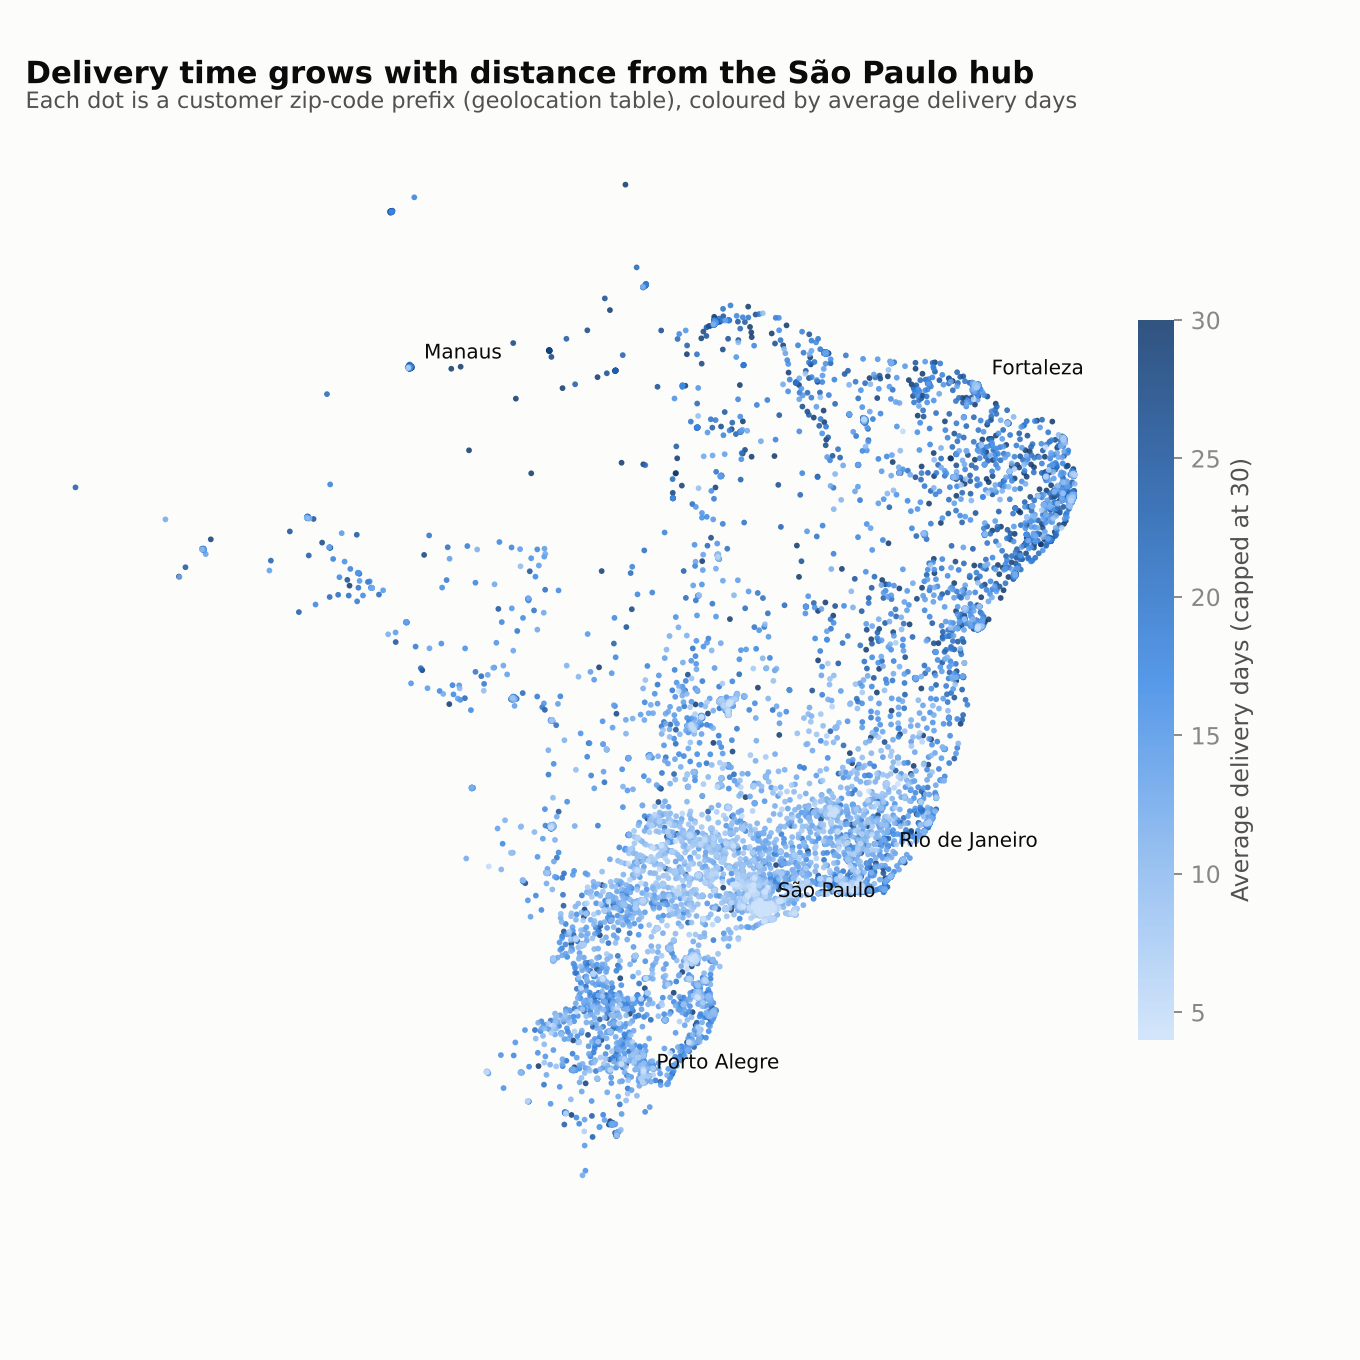

In [33]:
chart('14_delivery_time_map.png')

**Insights**
- Delivery time, freight and lateness move together: the North and North-East are slow, expensive and (in AL, MA, CE, SE, PI) often late.
- Among large states, RJ stands out with 13.5% late deliveries despite average speed, 2.3x SP's rate.

**Recommendations**
- Make RJ the first fix: it is the second-biggest market and has a lateness problem, not a distance problem.

## 6. Payments

### Q6.1 Month-on-month orders by payment type
> Find the month on month no. of orders placed using different payment types.

In [34]:
run('6.1')

SELECT
  FORMAT_TIMESTAMP('%Y-%m', o.order_purchase_timestamp) AS order_month,
  p.payment_type,
  COUNT(DISTINCT o.order_id) AS total_orders
FROM target.orders AS o
JOIN target.payments AS p
  ON o.order_id = p.order_id
GROUP BY order_month, p.payment_type
ORDER BY order_month, total_orders DESC;



90 rows


,order_month,payment_type,total_orders
0,2016-09,credit_card,3
1,2016-10,credit_card,253
2,2016-10,UPI,63
3,2016-10,voucher,11
4,2016-10,debit_card,2
5,2016-12,credit_card,1
6,2017-01,credit_card,582
7,2017-01,UPI,197
8,2017-01,voucher,33
9,2017-01,debit_card,9


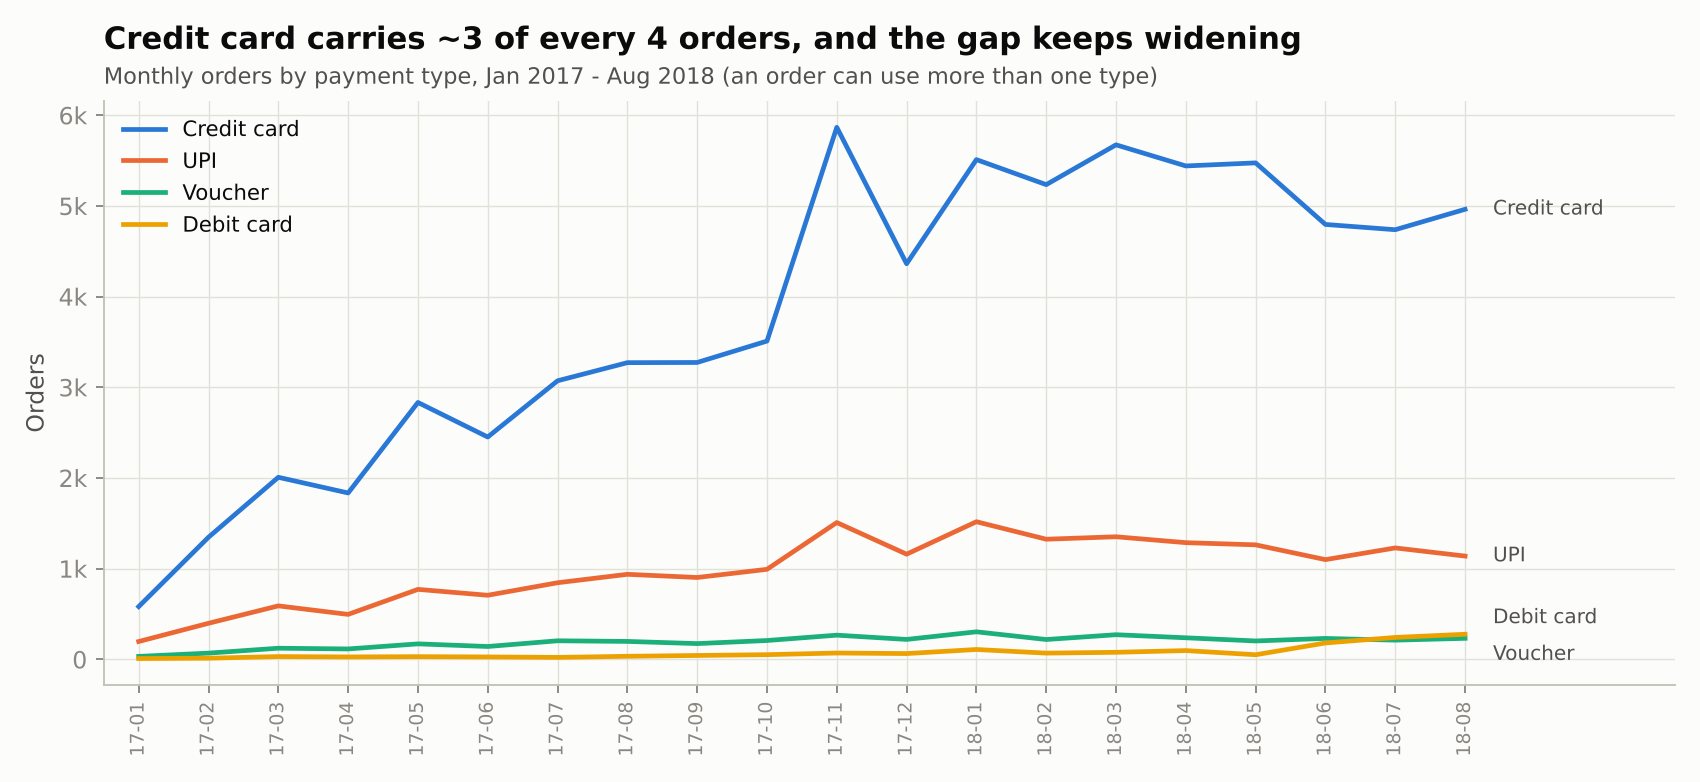

In [35]:
chart('11_payment_type_trend.png')

**Insights**
- Credit card is the dominant method every month and grew fastest, from 582 orders (Jan 2017) to ~5,000 a month in 2018.
- UPI is a steady second at ~1,100-1,500 orders a month. Voucher and debit card are small; debit card picked up in mid-2018.
- All methods peak together in November 2017.

**Recommendations**
- Partner with card issuers for interest-free installment campaigns around Black Friday, when card volume peaks.

### Q6.2 Payment type share, value and installments (supporting 6.1)
> Supporting view: share of orders and value by payment type.

In [36]:
run('6.2')

SELECT
  payment_type,
  COUNT(DISTINCT order_id) AS orders,
  ROUND(100 * COUNT(DISTINCT order_id) / (SELECT COUNT(DISTINCT order_id) FROM target.payments), 2)
    AS pct_of_orders,
  ROUND(SUM(payment_value), 2) AS total_value,
  ROUND(AVG(payment_value), 2) AS avg_payment_value,
  ROUND(AVG(payment_installments), 2) AS avg_installments
FROM target.payments
GROUP BY payment_type
ORDER BY orders DESC;



5 rows


,payment_type,orders,pct_of_orders,total_value,avg_payment_value,avg_installments
0,credit_card,76505,76.94,12542084.19,163.32,3.51
1,UPI,19784,19.90,2869361.27,145.03,1.00
2,voucher,3866,3.89,379436.87,65.70,1.00
3,debit_card,1528,1.54,217989.79,142.57,1.00
4,not_defined,3,0.00,0.00,0.00,1.00


**Insights**
- Credit card is used in 76.9% of orders and carries R$12.5M of value (average R$163, 3.5 installments).
- UPI covers 19.9% of orders; vouchers 3.9% with the smallest average ticket (R$65.7).

**Recommendations**
- Offer a small UPI discount to shift volume from card (lower fees) on low-value baskets.

### Q6.3 Number of orders by payment installments
> Find the no. of orders placed on the basis of the payment installments that have been paid.

In [37]:
run('6.3')

SELECT
  payment_installments,
  COUNT(DISTINCT order_id) AS total_orders,
  ROUND(100 * COUNT(DISTINCT order_id)
        / SUM(COUNT(DISTINCT order_id)) OVER (), 2) AS pct_of_orders,
  ROUND(AVG(payment_value), 2) AS avg_payment_value
FROM target.payments
GROUP BY payment_installments
ORDER BY payment_installments;

24 rows


,payment_installments,total_orders,pct_of_orders,avg_payment_value
0,0,2,0.00,94.32
1,1,49060,48.91,112.42
2,2,12389,12.35,127.23
3,3,10443,10.41,142.54
4,4,7088,7.07,163.98
5,5,5234,5.22,183.47
6,6,3916,3.90,209.85
7,7,1623,1.62,187.67
8,8,4253,4.24,307.74
9,9,644,0.64,203.44


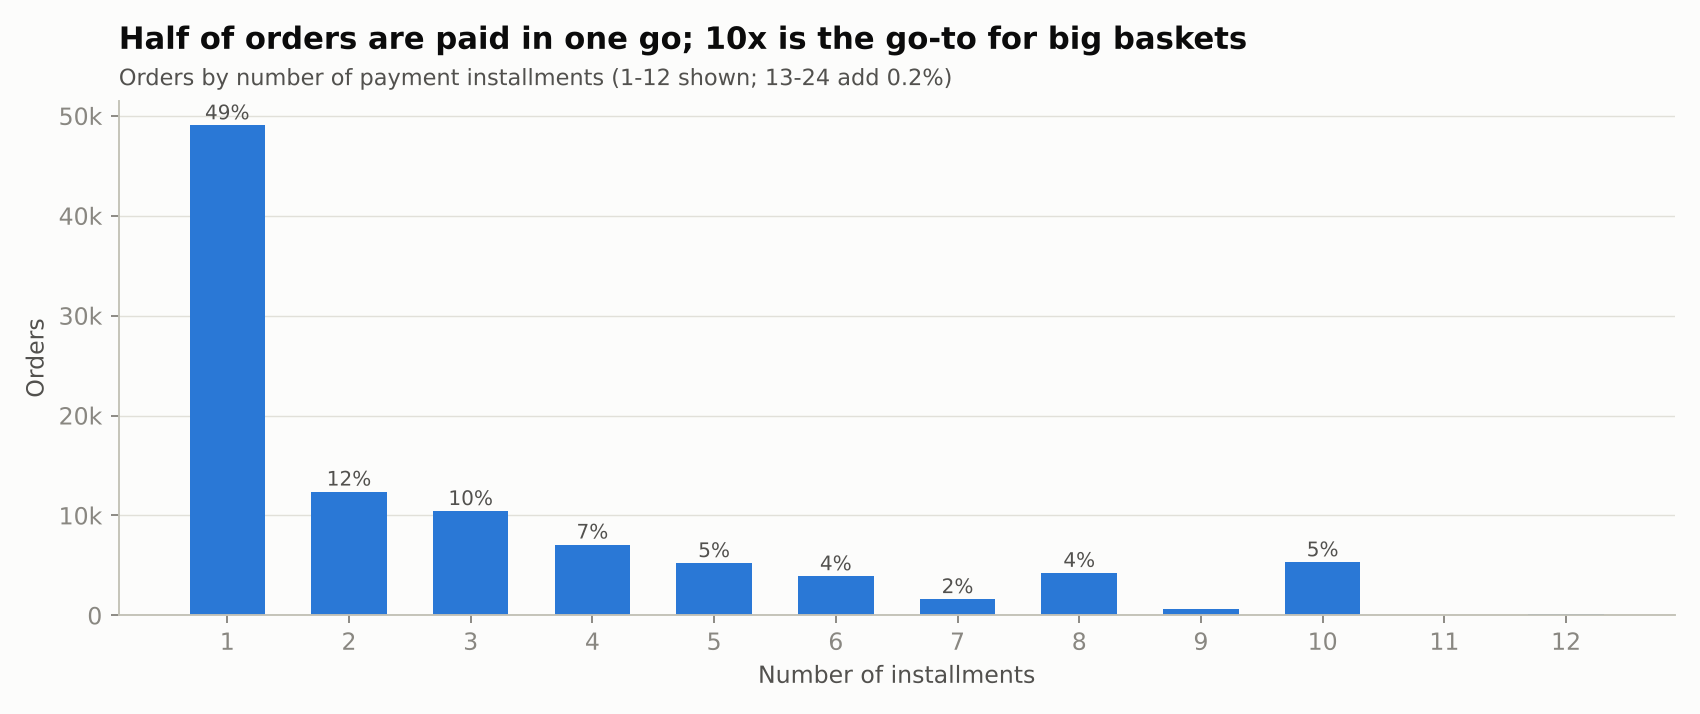

In [38]:
chart('12_installments.png')

**Insights**
- 48.9% of orders are paid in a single installment, 12.4% in 2 and 10.4% in 3.
- The average payment rises with installments: R$112 for 1, R$308 for 8, R$415 for 10. Installments are what make expensive items affordable.
- 10 installments (5.3% of orders) is a clear spike, the usual 'interest-free 10x' offer in Brazil.

**Recommendations**
- Promote interest-free installments on high-ticket categories (watches, electronics, furniture) to grow basket size.

## 7. Bonus deep-dives (beyond the brief)

### Q7.1 Does late delivery hurt review scores?
> Bonus: average review score and share of 1-star reviews by how early or late the order arrived.

In [39]:
run('7.1')

WITH d AS (
  SELECT
    o.order_id,
    TIMESTAMP_DIFF(o.order_delivered_customer_date, o.order_estimated_delivery_date, DAY) AS days_vs_estimate
  FROM target.orders AS o
  WHERE o.order_status = 'delivered'
    AND o.order_delivered_customer_date IS NOT NULL
),
r AS (
  SELECT order_id, AVG(review_score) AS review_score
  FROM target.order_reviews
  GROUP BY order_id
)
SELECT
  CASE
    WHEN d.days_vs_estimate <= -15 THEN '1. 15+ days early'
    WHEN d.days_vs_estimate <= -8  THEN '2. 8-14 days early'
    WHEN d.days_vs_estimate <= 0   THEN '3. 0-7 days early'
    WHEN d.days_vs_estimate <= 3   THEN '4. 1-3 days late'
    WHEN d.days_vs_estimate <= 7   THEN '5. 4-7 days late'
    ELSE                                '6. 8+ days late'
  END AS delivery_bucket,
  COUNT(*) AS orders,
  ROUND(AVG(r.review_score), 2) AS avg_review_score,
  ROUND(100 * AVG(CASE WHEN r.review_score <= 1 THEN 1 ELSE 0 END), 2) AS pct_1_star,
  ROUND(100 * AVG(CASE WHEN r.review_score >= 5 THEN 1 ELSE 0 END),

,delivery_bucket,orders,avg_review_score,pct_1_star,pct_5_star
0,1. 15+ days early,29453,4.32,6.66,64.15
1,2. 8-14 days early,36676,4.32,6.18,63.49
2,3. 0-7 days early,23314,4.20,7.11,57.75
3,4. 1-3 days late,1852,3.29,25.11,33.15
4,5. 4-7 days late,1748,2.11,58.47,14.07
5,6. 8+ days late,2781,1.70,69.72,7.01


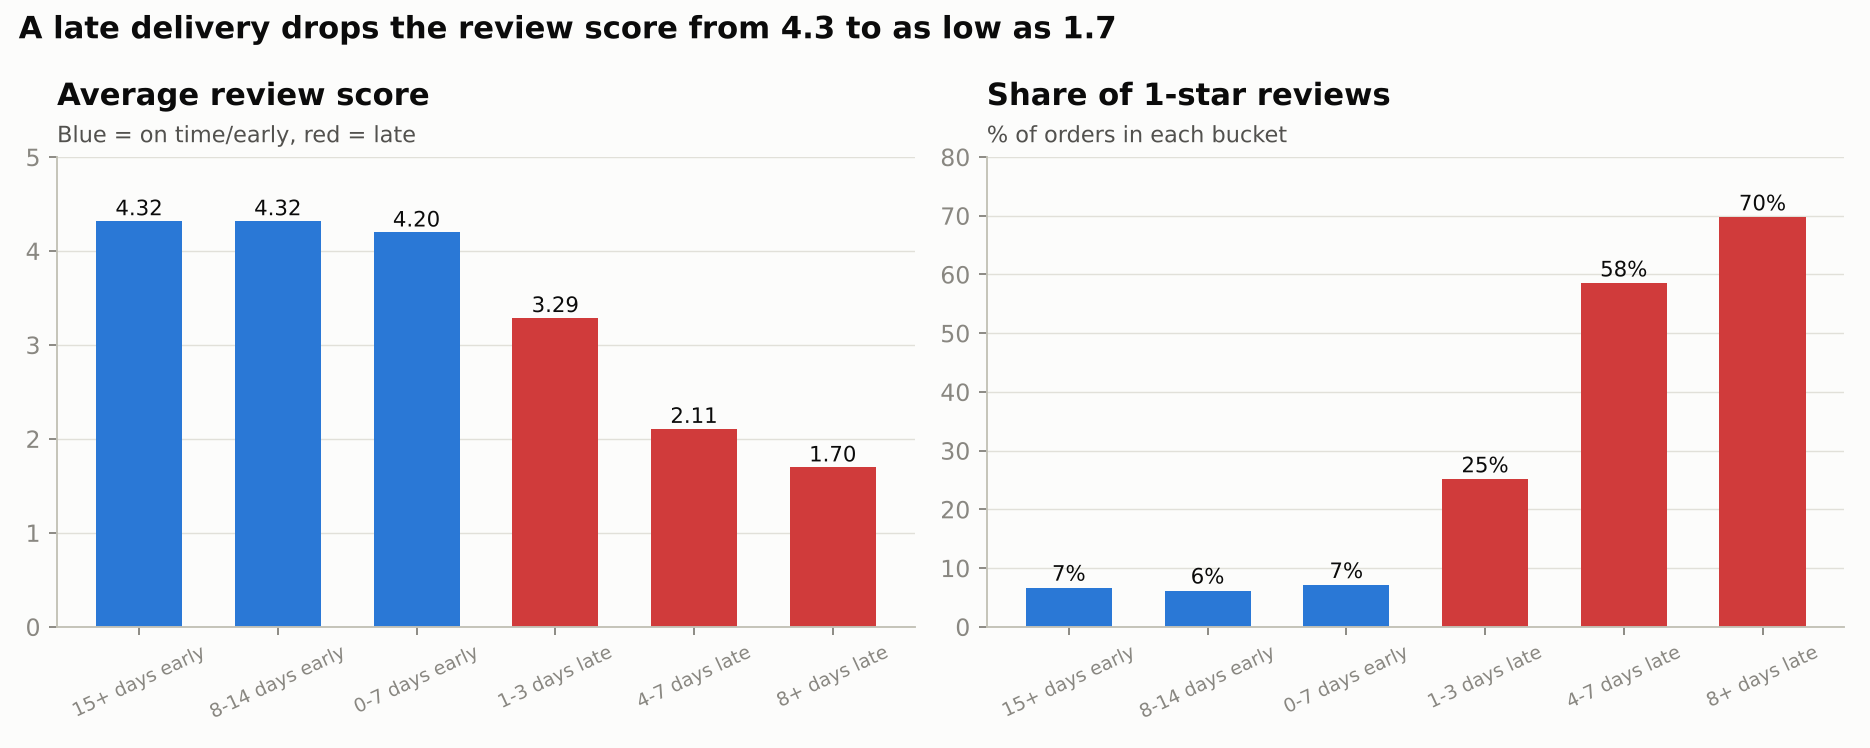

In [40]:
chart('10_review_score_vs_delivery_delay.png')

**Insights**
- Customers barely reward early delivery (4.32 stars at 15+ days early vs 4.20 at 0-7 days early), but they punish lateness hard: 3.29 at 1-3 days late, 2.11 at 4-7, 1.70 at 8+.
- 70% of orders delivered 8+ days late receive a 1-star review, vs 6-7% of on-time orders.

**Recommendations**
- Optimise for reliability (on-time %) rather than raw speed; it is the strongest single driver of ratings in the data.
- Proactively notify and compensate customers (voucher) when an order is predicted to be late.

### Q7.2 Same-state vs cross-state fulfilment
> Bonus: how much faster and cheaper is an order when the seller is in the customer's state?

In [41]:
run('7.2')

WITH item_level AS (
  SELECT
    o.order_id,
    CASE WHEN s.seller_state = c.customer_state THEN 'Same state' ELSE 'Cross state' END AS route,
    oi.freight_value,
    oi.price,
    TIMESTAMP_DIFF(o.order_delivered_customer_date, o.order_purchase_timestamp, DAY) AS actual_days,
    CASE WHEN TIMESTAMP_DIFF(o.order_delivered_customer_date, o.order_estimated_delivery_date, DAY) > 0 THEN 1 ELSE 0 END AS is_late
  FROM target.orders AS o
  JOIN target.customers   AS c  ON o.customer_id = c.customer_id
  JOIN target.order_items AS oi ON o.order_id = oi.order_id
  JOIN target.sellers     AS s  ON oi.seller_id = s.seller_id
  WHERE o.order_status = 'delivered'
    AND o.order_delivered_customer_date IS NOT NULL
)
SELECT
  route,
  COUNT(*) AS items,
  ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_items,
  ROUND(AVG(actual_days), 2) AS avg_delivery_days,
  ROUND(AVG(freight_value), 2) AS avg_freight,
  ROUND(100 * SUM(freight_value) / SUM(price), 2) AS freight_pct_of_price,
  R

2 rows


,route,items,pct_of_items,avg_delivery_days,avg_freight,freight_pct_of_price,pct_late
0,Cross state,70328,63.82,14.58,23.63,18.29,7.81
1,Same state,39861,36.18,7.46,13.45,12.97,4.45


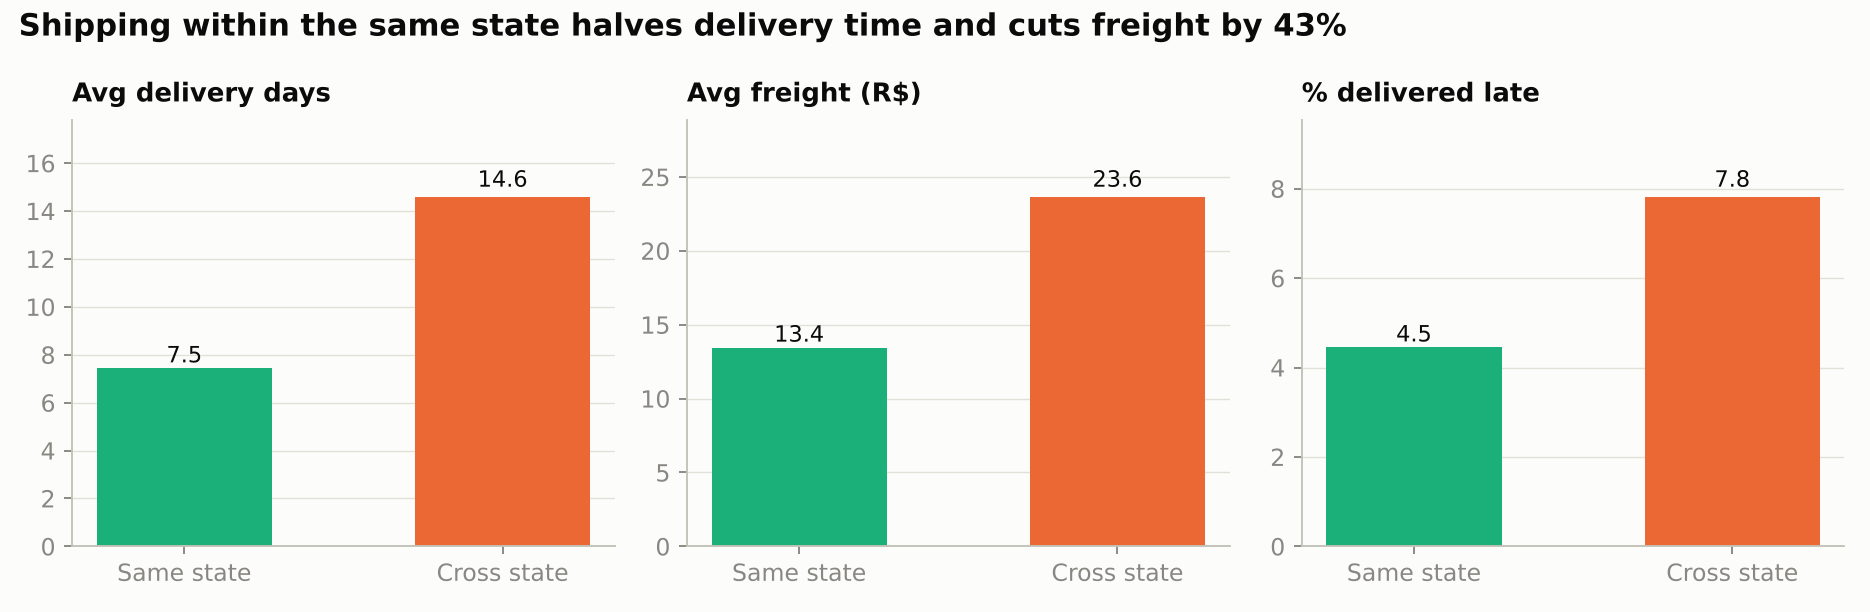

In [42]:
chart('13_same_vs_cross_state.png')

**Insights**
- 36.2% of items ship from a seller in the customer's own state.
- Those items arrive in 7.5 days vs 14.6 cross-state, pay R$13.45 vs R$23.63 freight (-43%), and are late 4.5% vs 7.8% of the time.

**Recommendations**
- Raising the same-state share is the single biggest logistics lever: recruit local sellers and prioritise local stock in search ranking.

### Q7.3 Where are the sellers? Seller vs customer concentration
> Bonus: share of sellers vs share of customers by state (supply-demand gap).

In [43]:
run('7.3')

WITH sellers_by_state AS (
  SELECT seller_state AS state, COUNT(*) AS sellers
  FROM target.sellers
  GROUP BY seller_state
),
customers_by_state AS (
  SELECT customer_state AS state, COUNT(DISTINCT customer_unique_id) AS customers
  FROM target.customers
  GROUP BY customer_state
)
SELECT
  c.state,
  c.customers,
  COALESCE(s.sellers, 0) AS sellers,
  ROUND(100 * c.customers / SUM(c.customers) OVER (), 2) AS pct_customers,
  ROUND(100 * COALESCE(s.sellers, 0) / SUM(COALESCE(s.sellers, 0)) OVER (), 2) AS pct_sellers,
  ROUND(c.customers / NULLIF(s.sellers, 0), 1) AS customers_per_seller
FROM customers_by_state AS c
LEFT JOIN sellers_by_state AS s ON c.state = s.state
ORDER BY c.customers DESC;



27 rows


,state,customers,sellers,pct_customers,pct_sellers,customers_per_seller
0,SP,40302,1849,41.92,59.74,21.8
1,RJ,12384,171,12.88,5.53,72.4
2,MG,11259,244,11.71,7.88,46.1
3,RS,5277,129,5.49,4.17,40.9
4,PR,4882,349,5.08,11.28,14.0
5,SC,3534,190,3.68,6.14,18.6
6,BA,3277,19,3.41,0.61,172.5
7,DF,2075,30,2.16,0.97,69.2
8,ES,1964,23,2.04,0.74,85.4
9,GO,1952,40,2.03,1.29,48.8


**Insights**
- 59.7% of sellers are in SP, which has 41.9% of customers.
- BA (172 customers per seller), PE (179) and RJ (72) are badly under-supplied, compared with 22 in SP.

**Recommendations**
- Run seller-acquisition drives in BA, PE, CE and RJ to localise supply for large, under-served markets.

### Q7.4 Top product categories by revenue
> Bonus: which categories drive revenue, and how satisfied are their buyers?

In [44]:
run('7.4')

WITH r AS (
  SELECT order_id, AVG(review_score) AS review_score
  FROM target.order_reviews
  GROUP BY order_id
)
SELECT
  COALESCE(p.product_category_name, 'unknown') AS category,
  COUNT(DISTINCT oi.order_id) AS orders,
  ROUND(SUM(oi.price), 2) AS revenue,
  ROUND(100 * SUM(oi.price) / SUM(SUM(oi.price)) OVER (), 2) AS pct_revenue,
  ROUND(AVG(oi.price), 2) AS avg_item_price,
  ROUND(AVG(r.review_score), 2) AS avg_review_score
FROM target.order_items AS oi
LEFT JOIN target.products AS p ON oi.product_id = p.product_id
LEFT JOIN r ON oi.order_id = r.order_id
GROUP BY category
ORDER BY revenue DESC
LIMIT 15;



15 rows


,category,orders,revenue,pct_revenue,avg_item_price,avg_review_score
0,HEALTH BEAUTY,8836,1258681.34,9.26,130.16,4.14
1,Watches present,5624,1205005.68,8.87,201.14,4.02
2,bed table bath,9417,1036988.68,7.63,93.30,3.90
3,sport leisure,7720,988048.97,7.27,114.34,4.11
4,computer accessories,6689,911954.32,6.71,116.51,3.93
5,Furniture Decoration,6449,729762.49,5.37,87.56,3.91
6,Cool Stuff,3632,635290.85,4.67,167.36,4.15
7,housewares,5884,632248.66,4.65,90.79,4.05
8,automotive,3897,592720.11,4.36,139.96,4.06
9,Garden tools,3518,485256.46,3.57,111.63,4.05


**Insights**
- Health & beauty (9.3% of revenue), watches & gifts (8.9%) and bed/table/bath (7.6%) lead revenue.
- Bed/table/bath, furniture/decor and computer accessories have the lowest ratings in the top 15 (3.90-3.93), pointing to quality or expectation gaps.

**Recommendations**
- Audit sellers and listings in low-rated, high-revenue categories (photos, size guides, packaging).

### Q7.5 How many customers come back?
> Bonus: distribution of customers by number of orders placed (uses customer_unique_id).

In [45]:
run('7.5')

WITH per_customer AS (
  SELECT c.customer_unique_id, COUNT(DISTINCT o.order_id) AS orders
  FROM target.orders AS o
  JOIN target.customers AS c ON o.customer_id = c.customer_id
  GROUP BY c.customer_unique_id
)
SELECT
  CASE WHEN orders >= 4 THEN '4+' ELSE CAST(orders AS STRING) END AS orders_per_customer,
  COUNT(*) AS customers,
  ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_customers
FROM per_customer
GROUP BY orders_per_customer
ORDER BY orders_per_customer;



4 rows


,orders_per_customer,customers,pct_of_customers
0,1,93099,96.88
1,2,2745,2.86
2,3,203,0.21
3,4+,49,0.05


**Insights**
- 96.9% of customers ordered only once; 2.9% ordered twice and just 0.26% three or more times.

**Recommendations**
- Launch a retention programme (post-delivery coupons, loyalty points, personalised recommendations). Even a few points of repeat rate is worth thousands of orders.

### Q7.6 Do peaks break the delivery network?
> Bonus: monthly share of late deliveries and average delivery time (delivered orders, Jan 2017 - Aug 2018).

In [46]:
run('7.6')

SELECT
  FORMAT_TIMESTAMP('%Y-%m', order_purchase_timestamp) AS order_month,
  COUNT(*) AS delivered_orders,
  ROUND(AVG(TIMESTAMP_DIFF(order_delivered_customer_date, order_purchase_timestamp, DAY)), 2) AS avg_delivery_days,
  ROUND(100 * AVG(CASE WHEN TIMESTAMP_DIFF(order_delivered_customer_date, order_estimated_delivery_date, DAY) > 0
                       THEN 1 ELSE 0 END), 2) AS pct_late
FROM target.orders
WHERE order_status = 'delivered'
  AND order_delivered_customer_date IS NOT NULL
  AND order_purchase_timestamp >= '2017-01-01'
  AND order_purchase_timestamp <  '2018-09-01'
GROUP BY order_month
ORDER BY order_month;



20 rows


,order_month,delivered_orders,avg_delivery_days,pct_late
0,2017-01,750,12.09,2.93
1,2017-02,1653,12.61,2.96
2,2017-03,2546,12.40,4.56
3,2017-04,2303,14.35,6.56
4,2017-05,3545,10.76,2.99
5,2017-06,3135,11.51,3.03
6,2017-07,3872,11.13,2.79
7,2017-08,4193,10.70,2.91
8,2017-09,4150,11.40,4.39
9,2017-10,4478,11.42,4.18


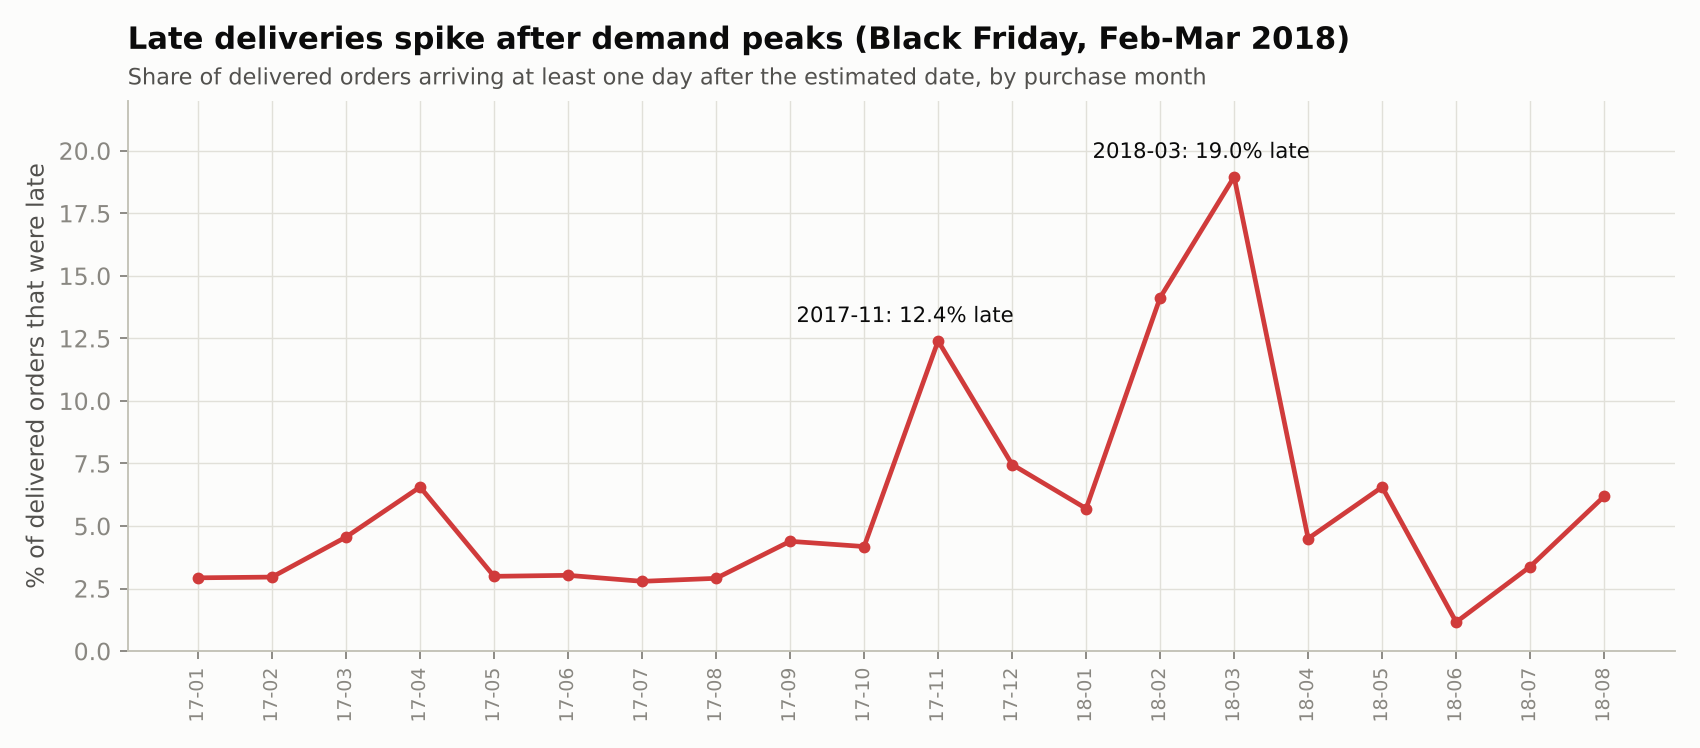

In [47]:
chart('15_late_delivery_rate_trend.png')

**Insights**
- Late deliveries are usually 3-5% of orders but jump after demand peaks: 12.4% in Nov 2017 and 14.1% / 19.0% in Feb / Mar 2018.
- Average delivery time improved to 7.7 days by Aug 2018, so the network can perform when it is not overloaded.

**Recommendations**
- Plan peak capacity (carriers, warehouse staff) 4-6 weeks ahead of Black Friday and the post-holiday surge, and widen estimates temporarily during peaks.

## 8. Actionable insights & recommendations
1. **Fix reliability before speed.** A late order loses 0.9-2.6 review stars; an early one gains almost nothing. Track on-time % as the headline logistics KPI, predict late orders and notify/compensate proactively. Start with RJ (13.5% late, second-largest market).
2. **Recalibrate delivery estimates per state.** Estimates are padded by 11 days on average and by up to 20 days in the North. Showing realistic dates at checkout improves conversion; adding buffer in AL and MA (20-24% late) protects reviews.
3. **Localise supply: regional sellers and a North/North-East cross-dock.** Same-state items arrive 2x faster with 43% lower freight. 60% of sellers sit in SP while BA, PE and RJ have 70-180 customers per seller. Recruit sellers there and pilot a cross-dock in the North-East.
4. **Make freight affordable in remote states.** Freight is 22-29% of the item price in the North/North-East vs 14% in SP. Bulk carrier contracts, subsidised shipping and free-shipping thresholds would unlock everyday purchases in markets that grew slowest.
5. **Plan peak capacity ahead of Black Friday and Q1.** Black Friday 2017 brought 5x a normal day's orders; late deliveries jumped to 12.4% that month and to 14-19% after the Q1 2018 surge. Pre-book carrier capacity and staff from October and temporarily widen estimates during peaks.
6. **Grow basket size with installments and bundles.** Average order value has been flat at ~R$160 for two years. 10x interest-free plans already carry R$415 tickets; promote them on high-ticket categories and add bundles and free-shipping thresholds.
7. **Build retention.** 97% of customers buy once. A loyalty programme, post-delivery coupons and personalised recommendations target the cheapest growth available, especially now that acquisition-led growth has plateaued.
8. **Time marketing to the afternoon and evening.** 38% of orders arrive 13:00-18:00 and 28% at night. Concentrate flash sales, push and paid-media budget in 13:00-22:00, and run maintenance at dawn.